# Eksperimen Machine Learning: Rekomendasi Menu dan Prediksi Keramaian Coffee Shop
**Proyek:** Sistem Rekomendasi Menu Coffee Shop Berbasis Waktu Menggunakan K-Nearest Neighbor (KNN)
**Dataset:** *Coffee Shop Sales* (Maven Analytics), data simulasi, cabang **Lower Manhattan** (`store_id = 5`), Januari–Juni 2023
**Tool:** Google Colab, Python, scikit-learn

---
## Peta notebook (baca ini dulu)

Notebook ini menjawab **dua pertanyaan penelitian**:

| Pertanyaan | Label (yang diprediksi) | Fitur (masukan) | Jenis tugas |
|---|---|---|---|
| **P1.** Apakah kategori menu yang dibeli bisa diprediksi dari waktu? | `product_category` (9 kelas, sudah ada di dataset) | jam, hari, akhir pekan, jam sinus/kosinus | Klasifikasi |
| **P2.** Apakah tingkat keramaian per jam bisa diprediksi dari waktu? | jumlah transaksi per jam (angka) dan kelas sepi/sedang/ramai (label turunan) | jam, hari, akhir pekan, bulan, jam sinus/kosinus | Regresi dan klasifikasi |

**Alur 11 tahap:**

| Tahap | Isi | Pertanyaan yang dijawab |
|---|---|---|
| 0 | Persiapan | Tools dan data sudah siap? |
| 1 | Memahami data dan label | Datanya apa, labelnya apa? |
| 2 | Kualitas data | Datanya bersih dan layak dipakai? |
| 3 | Preprocessing dan fitur | Fitur apa yang dibuat, dan mengapa? |
| 4 | Uji ketergantungan waktu | Apakah menu benar-benar berbeda menurut waktu? |
| 5 | Pembagian data dan baseline | Apa pembanding paling sederhana yang harus dikalahkan? |
| 6 | Eksperimen KNN | K berapa yang paling baik? |
| 7 | Perbandingan model | Apakah KNN lebih baik dari model lain dan dari baseline? |
| 8 | Evaluasi rinci dan interval kepercayaan | Selisihnya nyata atau kebetulan? |
| 9 | Tugas keramaian | Apakah keramaian bisa diprediksi, termasuk ke masa depan? |
| 10 | Ringkasan otomatis | Apa kesimpulan akhirnya? |

**Cara membaca setiap tahap.** Tiap tahap punya tiga bagian:
1. **Penjelasan tahap** (kotak teks sebelum kode): tujuan, apa yang dikerjakan, dan istilah penting.
2. **Kode dan keluaran** (sel kode): tabel dan grafik hasil.
3. **Kesimpulan tahap** (sel kode berjudul `KESIMPULAN`): kalimat penjelasan yang dibuat otomatis dari angka hasil, jadi selalu cocok dengan keluaran.

**Perubahan pada versi 4 (menanggapi tinjauan metodologi)**
| # | Perbaikan | Tahap |
|---|---|---|
| 1 | Interval kepercayaan memakai **bootstrap per tanggal** (bukan per baris); versi per baris tetap ditampilkan sebagai pembanding | 8, 9 |
| 2 | **Analisis slot jam kosong** dan analisis sensitivitas dengan jam kosong diisi 0 | 9A |
| 3 | **F1 makro baseline** untuk klasifikasi keramaian 3 kelas | 9B |
| 4 | **K temporal yang bersih**: K dipilih hanya dari data Januari–Mei untuk uji Juni | 6 |

> Prinsip yang dipegang: **semua model dibandingkan dengan baseline**, hasil negatif ikut dilaporkan, dan angka di laporan disalin dari keluaran, bukan dari ingatan.

## Tahap 0 – Persiapan
**Tujuan:** menyiapkan pustaka, aturan tampilan, dan data.

**Yang dikerjakan**
1. Mengimpor pustaka: `pandas` (tabel), `numpy` (hitung), `matplotlib` (grafik), `scipy` (uji statistik), `scikit-learn` (model).
2. Mengunci `SEED = 42` agar hasil sama setiap kali dijalankan (reprodusibel).
3. Mengatur tampilan tabel dan grafik agar rapi dan seragam.
4. Mengunggah dataset, lalu menghitung **SHA-256** (sidik jari berkas). Jika angkanya sama dengan yang tertulis di laporan, berarti data yang dipakai identik.

**Cara membaca keluaran:** baris pertama menampilkan versi pustaka; baris berikutnya nama berkas, ukuran, dan SHA-256.

In [1]:
import os, warnings, time, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.utils import resample
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 9, 'figure.autolayout': True})
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
def boot_blok(fn, tanggal, B=1000, seed=SEED):
    # Bootstrap per TANGGAL (blok): seluruh baris pada satu tanggal diambil/dibuang bersama (observasi sehari saling berkorelasi)
    tanggal = np.asarray(tanggal); ud = np.unique(tanggal); idx = {u: np.where(tanggal == u)[0] for u in ud}
    rng = np.random.default_rng(seed); vals = []
    for _ in range(B):
        pilih = rng.choice(ud, len(ud)); vals.append(fn(np.concatenate([idx[u] for u in pilih])))
    return np.percentile(vals, [2.5, 97.5])
def banner(judul):
    print('=' * 78); print(judul); print('=' * 78)
_T = ''
def kesimpulan(*baris):
    banner('KESIMPULAN TAHAP ' + str(_T))
    import textwrap
    for b in baris: print(textwrap.fill(b, width=105, initial_indent='• ', subsequent_indent='  '))
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


**Unggah dataset.** Jika berkas belum ada di Colab, pilih `Coffee Shop Sales.xlsx` lewat tombol **Choose Files**. Berkas Excel yang namanya diubah menjadi `.csv` tetap bisa dibaca.

In [2]:
DATA = 'Coffee Shop Sales.xlsx'
if not os.path.exists(DATA):
    from google.colab import files
    up = files.upload(); DATA = list(up.keys())[0]
sha = hashlib.sha256(open(DATA, 'rb').read()).hexdigest()
print('Berkas data:', DATA, '| ukuran:', round(os.path.getsize(DATA)/1e6, 2), 'MB')
print('SHA-256    :', sha)

Berkas data: Coffee Shop Sales.xlsx | ukuran: 8.97 MB
SHA-256    : 287d06d19f7a832d48f1deea7b149836fb32d591010f060bdcf8d1959653bfe1


## Tahap 1 – Memahami data dan label
**Tujuan:** mengetahui isi dataset dan menentukan **label** untuk machine learning.

**Penjelasan istilah**
- **Fitur** = informasi masukan model (di sini: waktu). **Label** = jawaban yang ingin diprediksi.
- Dataset ini **tidak punya kolom bernama `label`**. Label diambil dari kolom yang sudah ada: `product_category` (9 kelas), `product_type` (29 kelas), `product_detail` (80 kelas). Label utama yang dipakai adalah **`product_category`** karena paling ringkas dan cocok untuk rekomendasi menu.
- Label kedua **diturunkan**: jumlah transaksi per jam menjadi ukuran keramaian (Tahap 9).
- Satu baris data = satu item transaksi. Tidak ada ID pelanggan atau keranjang, sehingga model "pelanggan yang membeli A juga membeli B" tidak bisa dibuat.

**Yang dikerjakan:** membaca data mentah (3 cabang), menyaring cabang **Lower Manhattan**, lalu menghitung jumlah kelas dan distribusi label.

**Cara membaca keluaran**
- *Tabel 3 baris pertama:* contoh isi data.
- *Daftar `store_location`:* jumlah transaksi per cabang; hanya Lower Manhattan yang dipakai.
- *Grafik batang:* jumlah transaksi per kategori. Batang yang jauh lebih panjang menandakan **kelas dominan**.
- *Persentase:* kelas terbanyak menentukan **baseline mayoritas**, yaitu akurasi jika model selalu menebak kelas terbanyak tanpa belajar apa pun.

In [3]:
def baca(path):
    try:   return pd.read_excel(path, sheet_name='Transactions')
    except Exception: return pd.read_csv(path)
raw = baca(DATA)
print('Bentuk data mentah:', raw.shape); display(raw.head(3))
df = raw[raw['store_location'] == 'Lower Manhattan'].copy()
print('Lower Manhattan:', len(df), '| store_id unik:', df['store_id'].unique())
print(raw['store_location'].value_counts().to_string())

Bentuk data mentah: (149116, 11)


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.00,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg


Lower Manhattan: 47782 | store_id unik: [5]
store_location
Hell's Kitchen     50735
Astoria            50599
Lower Manhattan    47782


product_category  :   9 kelas
product_type      :  29 kelas
product_detail    :  80 kelas


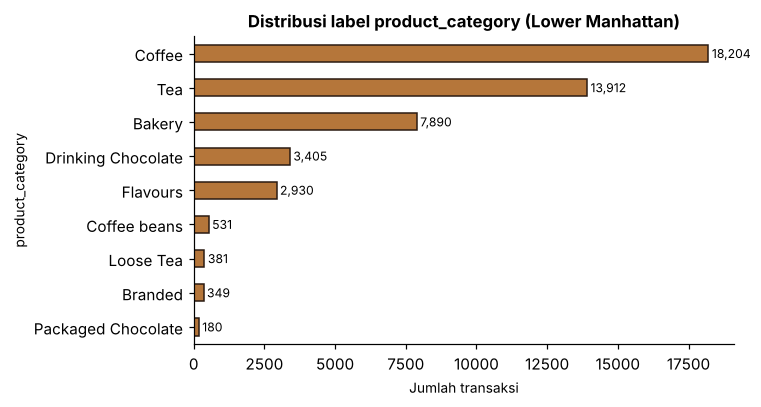

product_category
Coffee               38.10
Tea                  29.12
Bakery               16.51
Drinking Chocolate    7.13
Flavours              6.13
Coffee beans          1.11
Loose Tea             0.80
Branded               0.73
Packaged Chocolate    0.38

Kelas mayoritas = Coffee (38.10%) -> baseline akurasi paling sederhana


In [4]:
for c in ['product_category', 'product_type', 'product_detail']:
    print(f'{c:18s}: {df[c].nunique():3d} kelas')
vc = df['product_category'].value_counts()
ax = vc.sort_values().plot.barh(color='#B5763A', edgecolor='#2B1B12', figsize=(7, 3.8))
ax.set_xlabel('Jumlah transaksi'); ax.set_title('Distribusi label product_category (Lower Manhattan)')
for i, v in enumerate(vc.sort_values()): ax.text(v, i, f' {v:,}', va='center', fontsize=8)
plt.tight_layout(); plt.show()
print((vc / vc.sum() * 100).round(2).to_string())
print('\nKelas mayoritas =', vc.index[0], f'({vc.iloc[0]/vc.sum()*100:.2f}%) -> baseline akurasi paling sederhana')

In [5]:
_T = '1'
kesimpulan(f'Data Lower Manhattan: {len(df):,} baris transaksi dari total {len(raw):,} baris (3 cabang).',
           f'Label utama product_category punya {df.product_category.nunique()} kelas; kelas terbanyak: {vc.index[0]} ({vc.iloc[0]/vc.sum()*100:.2f}%).',
           f'Artinya sebuah model yang selalu menebak "{vc.index[0]}" sudah akurat {vc.iloc[0]/vc.sum()*100:.2f}%. Angka ini adalah batas bawah yang wajib dilampaui model apa pun.',
           f'Tiga kelas paling langka ({", ".join(vc.index[-3:])}) hanya {vc.iloc[-3:].sum()/vc.sum()*100:.2f}% dari data, sehingga sulit dipelajari model.')

KESIMPULAN TAHAP 1
• Data Lower Manhattan: 47,782 baris transaksi dari total 149,116 baris (3 cabang).
• Label utama product_category punya 9 kelas; kelas terbanyak: Coffee (38.10%).
• Artinya sebuah model yang selalu menebak "Coffee" sudah akurat 38.10%. Angka ini adalah batas bawah
  yang wajib dilampaui model apa pun.
• Tiga kelas paling langka (Loose Tea, Branded, Packaged Chocolate) hanya 1.90% dari data, sehingga sulit
  dipelajari model.


## Tahap 2 – Pengecekan kualitas data
**Tujuan:** memastikan data bersih sebelum dipakai (data kotor membuat hasil menyesatkan).

**Yang diperiksa**
| Pemeriksaan | Arti | Hasil yang diharapkan |
|---|---|---|
| Missing value | sel kosong | 0 |
| Duplikat | baris atau `transaction_id` ganda | 0 |
| Rentang `transaction_qty`, `unit_price` | nilai tidak masuk akal (nol atau negatif) | minimum > 0 |
| Rentang jam dan tanggal | jam buka dan periode data | jam 6–20, Jan–Jun 2023 |
| `product_id` ambigu | satu produk dengan kategori berbeda | 0 |
| Outlier (aturan IQR) | nilai jauh di luar sebaran | ditandai, **tidak dibuang** (transaksi sah) |

**Cara membaca keluaran:** daftar pemeriksaan dan hasilnya. Baris `Gerbang kualitas data: LULUS` muncul hanya jika semua syarat terpenuhi (`assert` akan menghentikan notebook jika ada yang gagal).

In [6]:
qc = {}
wajib = ['transaction_id','transaction_date','transaction_time','transaction_qty','store_id','store_location','product_id','unit_price','product_category','product_type','product_detail']
qc['kolom_wajib_ada'] = set(wajib).issubset(df.columns)
qc['total_missing'] = int(df.isna().sum().sum())
qc['duplikat_baris_penuh'] = int(df.duplicated().sum())
qc['duplikat_transaction_id'] = int(df['transaction_id'].duplicated().sum())
qc['qty_min_max'] = (int(df.transaction_qty.min()), int(df.transaction_qty.max()))
qc['harga_min_max'] = (float(df.unit_price.min()), float(df.unit_price.max()))
df['jam'] = df['transaction_time'].astype(str).str[:2].astype(int)
qc['jam_min_max'] = (int(df.jam.min()), int(df.jam.max()))
df['transaction_date'] = pd.to_datetime(df['transaction_date'])
qc['rentang_tanggal'] = (str(df.transaction_date.min().date()), str(df.transaction_date.max().date()))
qc['jumlah_hari'] = int(df.transaction_date.nunique())
qc['product_id_ambigu'] = int((df.groupby('product_id')[['product_category','product_type','product_detail']].nunique() > 1).any(axis=1).sum())
for k, v in qc.items(): print(f'{k:26s}: {v}')
assert qc['total_missing'] == 0 and qc['duplikat_transaction_id'] == 0 and qc['qty_min_max'][0] > 0 and qc['harga_min_max'][0] > 0
print('\nGerbang kualitas data: LULUS')
def iqr_out(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5*i) | (s > q3 + 1.5*i)
print('Outlier qty:', int(iqr_out(df.transaction_qty).sum()), '| outlier harga:', int(iqr_out(df.unit_price).sum()), '(ditandai, dipertahankan: transaksi sah)')

kolom_wajib_ada           : True
total_missing             : 0
duplikat_baris_penuh      : 0
duplikat_transaction_id   : 0
qty_min_max               : (1, 6)
harga_min_max             : (0.8, 45.0)
jam_min_max               : (6, 20)
rentang_tanggal           : ('2023-01-01', '2023-06-30')
jumlah_hari               : 181
product_id_ambigu         : 0

Gerbang kualitas data: LULUS
Outlier qty: 26 | outlier harga: 1456 (ditandai, dipertahankan: transaksi sah)


In [7]:
_T = '2'
kesimpulan(f'Tidak ada missing value ({qc["total_missing"]}) dan tidak ada duplikat transaksi ({qc["duplikat_transaction_id"]}): data layak dipakai tanpa pembersihan.',
           f'Periode {qc["rentang_tanggal"][0]} s.d. {qc["rentang_tanggal"][1]} ({qc["jumlah_hari"]} hari), jam operasional {qc["jam_min_max"][0]}.00–{qc["jam_min_max"][1]}.59.',
           'Outlier harga berasal dari produk mahal yang sah (mis. biji kopi, merchandise), jadi dipertahankan.')

KESIMPULAN TAHAP 2
• Tidak ada missing value (0) dan tidak ada duplikat transaksi (0): data layak dipakai tanpa pembersihan.
• Periode 2023-01-01 s.d. 2023-06-30 (181 hari), jam operasional 6.00–20.59.
• Outlier harga berasal dari produk mahal yang sah (mis. biji kopi, merchandise), jadi dipertahankan.


## Tahap 3 – Preprocessing dan rekayasa fitur
**Tujuan:** mengubah kolom waktu mentah menjadi fitur numerik yang bisa dipakai model.

**Fitur yang dibuat**
| Fitur | Isi | Alasan |
|---|---|---|
| `jam` | 6–20 | Pola harian. |
| `hari_minggu` | 0 (Senin) – 6 (Minggu) | Pola mingguan. |
| `is_weekend` | 0 atau 1 | Penanda akhir pekan. |
| `bulan` | 1–6 | Dipakai hanya untuk tugas keramaian (tren pertumbuhan). |
| `jam_sin`, `jam_cos` | sinus dan kosinus jam | Jam bersifat melingkar: pukul 23 dan pukul 0 sebenarnya berdekatan. |
| `segmen` | pagi / siang / sore / malam | Untuk tabel dan uji statistik (bukan fitur model). |

**Mengapa `transaction_id`, `product_id`, `unit_price`, `product_type`, `product_detail` tidak dipakai sebagai fitur?** Kolom-kolom itu memuat jawaban secara langsung (**kebocoran label**), sehingga akurasi terlihat bagus padahal model tidak belajar apa pun dari waktu.

**Cara membaca keluaran:** jumlah kombinasi fitur yang unik, dan jumlah transaksi per segmen.

> **Temuan penting:** fitur klasifikasi sebenarnya hanya `jam` (15 nilai) dan `hari_minggu` (7 nilai); fitur lain turunan keduanya. Maka hanya ada **15 × 7 = 105 kombinasi unik**. Semua transaksi yang terjadi pada jam dan hari yang sama punya fitur yang persis sama, sehingga model tidak mungkin membedakan mereka.

In [8]:
df['hari_minggu'] = df['transaction_date'].dt.dayofweek
df['is_weekend'] = (df['hari_minggu'] >= 5).astype(int)
df['bulan'] = df['transaction_date'].dt.month
segmen = lambda j: 'pagi' if 6 <= j <= 10 else 'siang' if 11 <= j <= 14 else 'sore' if 15 <= j <= 17 else 'malam' if 18 <= j <= 20 else 'luar_jam'
df['segmen'] = df['jam'].map(segmen)
w = df['jam'] + 0.5
df['jam_sin'] = np.sin(2*np.pi*w/24); df['jam_cos'] = np.cos(2*np.pi*w/24)
FITUR = ['jam', 'hari_minggu', 'is_weekend', 'jam_sin', 'jam_cos']
print('Kombinasi fitur unik:', len(df[FITUR].drop_duplicates()), '(= 15 jam x 7 hari)')
print(df['segmen'].value_counts().to_string())

Kombinasi fitur unik: 105 (= 15 jam x 7 hari)
segmen
pagi     26700
siang    11076
sore      8379
malam     1627


## Tahap 4 – Uji ketergantungan terhadap waktu
**Tujuan:** menguji secara statistik apakah **jenis menu** dan **jumlah pembeli** benar-benar bergantung pada waktu. Ini menentukan apakah rekomendasi berbasis waktu masuk akal.

**Dua uji**
1. **Chi-kuadrat dan Cramér's V** untuk kategori menu × segmen waktu.
   - p-value kecil saja **tidak cukup** pada data besar (47 ribu baris membuat selisih sekecil apa pun tampak "signifikan").
   - Karena itu dilihat **Cramér's V** (ukuran kekuatan hubungan, 0–1): < 0,1 = sangat lemah, 0,1–0,3 = lemah, > 0,3 = sedang.
2. **Kruskal-Wallis** untuk jumlah transaksi per jam × jam. Uji ini tidak mengandaikan data berdistribusi normal.

**Cara membaca keluaran:** tabel persentase memperlihatkan komposisi menu di tiap segmen. Jika baris-barisnya hampir sama, komposisi menu tidak berubah menurut waktu.

In [9]:
tab = pd.crosstab(df['segmen'], df['product_category'])
chi2, p, dof, _ = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f'Kategori x segmen : chi2={chi2:.1f}, dof={dof}, p={p:.3g}, Cramér V={V:.4f}  (V ~ 0 = asosiasi sangat lemah)')
display((pd.crosstab(df['segmen'], df['product_category'], normalize='index') * 100).round(1))
agg = df.groupby(['transaction_date', 'jam']).size().reset_index(name='n_transaksi')
H, pk = stats.kruskal(*[g['n_transaksi'].values for _, g in agg.groupby('jam')])
print(f'Volume x jam      : Kruskal-Wallis H={H:.1f}, p={pk:.3g}')

Kategori x segmen : chi2=161.2, dof=24, p=2.63e-22, Cramér V=0.0335  (V ~ 0 = asosiasi sangat lemah)


product_category,Bakery,Branded,Coffee,Coffee beans,Drinking Chocolate,Flavours,Loose Tea,Packaged Chocolate,Tea
segmen,,,,,,,,,
malam,16.30,1.40,41.20,0.60,6.10,5.00,0.60,0.30,28.50
pagi,16.90,0.80,36.70,1.30,7.00,6.90,0.90,0.40,29.10
siang,16.50,0.70,39.00,1.00,7.40,5.00,0.60,0.30,29.40
sore,15.30,0.60,40.70,0.80,7.20,5.30,0.80,0.30,29.00


Volume x jam      : Kruskal-Wallis H=1016.9, p=3.78e-208


In [10]:
_T = '4'
kesimpulan(f'Komposisi MENU hampir tidak berubah menurut waktu: Cramér V = {V:.4f} (< 0,1 = hubungan sangat lemah), walaupun p-value sangat kecil karena datanya besar.',
           f'JUMLAH PEMBELI sangat bergantung pada jam: Kruskal-Wallis H = {H:.0f}, p = {pk:.2g}.',
           'Implikasi: waktu sangat berguna untuk memprediksi KERAMAIAN, tetapi hampir tidak berguna untuk memprediksi JENIS MENU. Dua hasil ini menjadi dasar seluruh tahap berikutnya.')

KESIMPULAN TAHAP 4
• Komposisi MENU hampir tidak berubah menurut waktu: Cramér V = 0.0335 (< 0,1 = hubungan sangat lemah),
  walaupun p-value sangat kecil karena datanya besar.
• JUMLAH PEMBELI sangat bergantung pada jam: Kruskal-Wallis H = 1017, p = 3.8e-208.
• Implikasi: waktu sangat berguna untuk memprediksi KERAMAIAN, tetapi hampir tidak berguna untuk
  memprediksi JENIS MENU. Dua hasil ini menjadi dasar seluruh tahap berikutnya.


## Tahap 5 – Pembagian data dan baseline
**Tujuan:** menyiapkan data latih dan data uji, dan menetapkan **pembanding sederhana (baseline)**.

**Penjelasan istilah**
- **Data latih** dipakai model belajar; **data uji** dipakai menilai (tidak boleh dilihat saat belajar).
- **Split acak 80:20** (*stratified*: proporsi kelas dijaga sama): data diacak lalu 80% untuk latih dan 20% untuk uji.
- **Split temporal**: latih Januari–Mei, uji Juni. Ini meniru pemakaian nyata (memprediksi masa depan) sehingga lebih ketat.
- **Baseline** adalah tebakan tanpa belajar. Model hanya dianggap berguna jika **mengalahkan baseline**.

**Tiga baseline yang dipakai**
| Baseline | Cara kerja | Dipakai untuk |
|---|---|---|
| Mayoritas | selalu menebak kelas terbanyak | akurasi |
| Top-3 terpopuler | selalu merekomendasikan 3 kategori terlaris | metrik top-3 (apakah jawaban benar ada di 3 rekomendasi) |
| Modus per (jam, hari) | di tiap kombinasi jam-hari, tebak kategori terbanyak pada data latih | pembanding yang paling adil untuk KNN, karena KNN hanya bisa belajar dari kombinasi jam-hari |

**Cara membaca keluaran:** jumlah data tiap skema, tiga baseline untuk tiap skema, dan tabel kategori terbanyak di 105 sel jam-hari.

In [11]:
le = LabelEncoder(); y = le.fit_transform(df['product_category']); KELAS = list(le.classes_)
X = df[FITUR].values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
mtr = (df['bulan'] <= 5).values
Xtr_t, ytr_t, Xte_t, yte_t = X[mtr], y[mtr], X[~mtr], y[~mtr]
_, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED, stratify=y)
assert (y[idx_te] == yte).all()
TGL_ACAK = df['transaction_date'].values[idx_te]; TGL_TEMP = df['transaction_date'].values[~mtr]   # tanggal tiap baris uji (untuk bootstrap per tanggal)
print(f'Split acak    : latih={len(ytr):,}  uji={len(yte):,}\nSplit temporal: latih={len(ytr_t):,}  uji={len(yte_t):,}')

def top_k(proba, ytrue, k=3):
    return float(np.mean([t in np.argsort(r)[-k:] for t, r in zip(ytrue, proba)]))

def baselines(Xa, ya, Xb, yb):
    cnt = np.bincount(ya, minlength=len(KELAS))
    out = {'mayoritas': float(np.mean(yb == cnt.argmax())),
           'top3_terpopuler': float(np.mean([t in np.argsort(cnt)[-3:] for t in yb]))}
    d = pd.DataFrame({'jam': Xa[:, 0], 'hari': Xa[:, 1], 'y': ya})
    modus = d.groupby(['jam', 'hari'])['y'].agg(lambda s: s.mode()[0])
    pred = [modus.get((j, h), cnt.argmax()) for j, h in zip(Xb[:, 0], Xb[:, 1])]
    out['modus_jam_hari'] = float(np.mean(np.array(pred) == yb))
    out['_modus_tabel'] = modus
    return out
B_acak = baselines(Xtr, ytr, Xte, yte); B_temp = baselines(Xtr_t, ytr_t, Xte_t, yte_t)
for nama, B in [('acak', B_acak), ('temporal', B_temp)]:
    print(f'Baseline [{nama}] mayoritas={B["mayoritas"]*100:.2f}% | modus jam-hari={B["modus_jam_hari"]*100:.2f}% | top-3 terpopuler={B["top3_terpopuler"]*100:.2f}%')
modus_all = df.groupby(['jam', 'hari_minggu'])['product_category'].agg(lambda s: s.value_counts().index[0])
print('\nKategori terbanyak di setiap sel jam-hari (105 sel):'); print(modus_all.value_counts().to_string())

Split acak    : latih=38,225  uji=9,557
Split temporal: latih=36,486  uji=11,296


Baseline [acak] mayoritas=38.10% | modus jam-hari=38.11% | top-3 terpopuler=83.73%
Baseline [temporal] mayoritas=38.79% | modus jam-hari=38.65% | top-3 terpopuler=83.73%

Kategori terbanyak di setiap sel jam-hari (105 sel):
product_category
Coffee    97
Tea        8


In [12]:
_T = '5'
kesimpulan(f'Baseline mayoritas = {B_acak["mayoritas"]*100:.2f}%, modus jam-hari = {B_acak["modus_jam_hari"]*100:.2f}%, top-3 terpopuler = {B_acak["top3_terpopuler"]*100:.2f}% (split acak).',
           f'Baseline modus jam-hari TIDAK lebih baik dari mayoritas (selisih {abs(B_acak["modus_jam_hari"]-B_acak["mayoritas"])*100:.2f} poin), karena di {int((modus_all=="Coffee").sum())} dari {len(modus_all)} sel jam-hari kategori terbanyaknya tetap Coffee.',
           'Artinya mengetahui jam dan hari hampir tidak menambah informasi tentang menu yang dibeli.')

KESIMPULAN TAHAP 5
• Baseline mayoritas = 38.10%, modus jam-hari = 38.11%, top-3 terpopuler = 83.73% (split acak).
• Baseline modus jam-hari TIDAK lebih baik dari mayoritas (selisih 0.01 poin), karena di 97 dari 105 sel
  jam-hari kategori terbanyaknya tetap Coffee.
• Artinya mengetahui jam dan hari hampir tidak menambah informasi tentang menu yang dibeli.


## Tahap 6 – Eksperimen KNN
**Tujuan:** mencari nilai **K** (jumlah tetangga) dan pengaturan KNN terbaik.

**Cara kerja KNN:** untuk data baru, cari K data latih yang fiturnya paling mirip (tetangga), lalu ambil suara terbanyak. K kecil = model sangat peka terhadap noise; K besar = model makin "rata-rata" dan akhirnya selalu menebak kelas mayoritas.

**6A. Pemilihan K** pada rentang lebar 1–800 (skala logaritmik) dengan *cross-validation* 5 lipatan (data latih dibagi 5, bergantian 4 bagian untuk belajar dan 1 bagian untuk menilai). Dua ukuran dibandingkan:
- **Akurasi:** persentase tebakan benar. Pada data timpang, akurasi bisa "tinggi" hanya dengan menebak kelas besar.
- **F1 makro:** rata-rata F1 dari semua kelas dengan bobot sama, sehingga kelas langka sama pentingnya. Lebih jujur untuk data timpang.

**6B. Pengaturan lain** (grid search): standarisasi fitur (menyamakan skala), jenis jarak (euclidean, manhattan), dan pembobotan tetangga (seragam, atau berdasarkan jarak).

**Cara membaca keluaran**
- *Grafik kiri:* akurasi CV vs K. Garis putus merah = baseline mayoritas. Jika kurva naik mendekati garis merah, KNN hanya menjadi penebak kelas terbanyak.
- *Grafik kanan:* F1 makro vs K. Jika turun saat K naik, model makin mengabaikan kelas langka.
- *Tabel 6B:* jika semua konfigurasi hampir sama, pengaturan jarak/bobot tidak penting.

(37 dtk) K terbaik menurut akurasi CV = 600 (38.10%) | menurut F1 makro CV = 1 (10.90%)


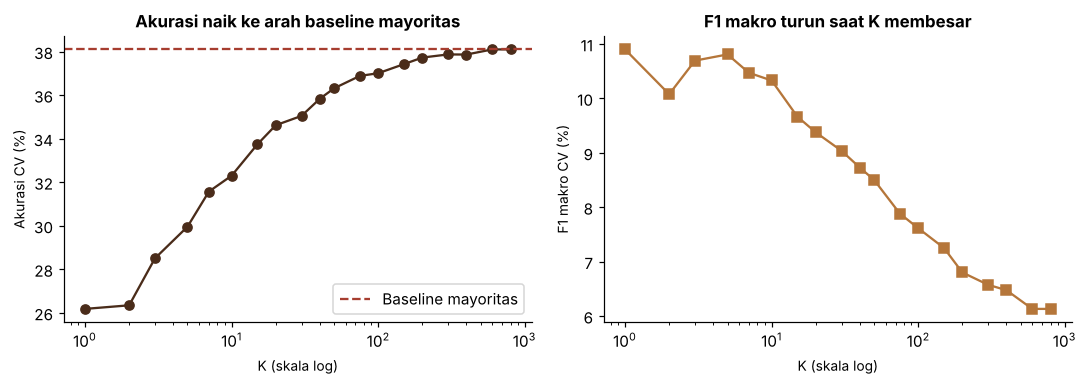

,K,akurasi_cv_%,f1_makro_cv_%
0,1,26.18,10.90
1,2,26.34,10.07
2,3,28.50,10.69
3,5,29.95,10.81
4,7,31.57,10.47
5,10,32.30,10.33
6,15,33.74,9.66
7,20,34.62,9.37
8,30,35.05,9.03
9,40,35.83,8.73


In [13]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 300, 400, 600, 800]
t0 = time.time(); cv_acc, cv_f1 = [], []
for k in ks:
    pipe = Pipeline([('s', StandardScaler()), ('knn', KNeighborsClassifier(k))])
    cv_acc.append(cross_val_score(pipe, Xtr, ytr, cv=skf, scoring='accuracy', n_jobs=-1).mean())
    cv_f1.append(cross_val_score(pipe, Xtr, ytr, cv=skf, scoring='f1_macro', n_jobs=-1).mean())
K_ACC = ks[int(np.argmax(cv_acc))]; K_F1 = ks[int(np.argmax(cv_f1))]; K_UTAMA = 20
print(f'({time.time()-t0:.0f} dtk) K terbaik menurut akurasi CV = {K_ACC} ({max(cv_acc)*100:.2f}%) | menurut F1 makro CV = {K_F1} ({max(cv_f1)*100:.2f}%)')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].semilogx(ks, np.array(cv_acc)*100, 'o-', color='#4A2C1A'); ax[0].axhline(B_acak['mayoritas']*100, color='#A63D2F', ls='--', label='Baseline mayoritas')
ax[0].set_xlabel('K (skala log)'); ax[0].set_ylabel('Akurasi CV (%)'); ax[0].legend(); ax[0].set_title('Akurasi naik ke arah baseline mayoritas')
ax[1].semilogx(ks, np.array(cv_f1)*100, 's-', color='#B5763A'); ax[1].set_xlabel('K (skala log)'); ax[1].set_ylabel('F1 makro CV (%)'); ax[1].set_title('F1 makro turun saat K membesar')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'K': ks, 'akurasi_cv_%': np.round(np.array(cv_acc)*100, 2), 'f1_makro_cv_%': np.round(np.array(cv_f1)*100, 2)}))

**Cara membaca:** kedua kriteria saling bertentangan. Akurasi CV terus naik sampai menyamai baseline mayoritas (K besar = penebak "Coffee" saja), sedangkan F1 makro tertinggi ada di K=1 (model menebak banyak kelas secara acak, akurasi jauh di bawah baseline). **Tidak ada K yang benar-benar baik**, dan itu adalah temuan, bukan kesalahan kode.

Karena itu K utama untuk analisis rinci adalah **K=20** (nilai yang dipakai aplikasi di repo; titik tengah di antara dua ekstrem). Dua ekstrem (`K_F1`, `K_ACC`) tetap diuji dan dilaporkan sebagai pembanding.

In [14]:
grid = {'knn__n_neighbors': [5, 15, 40, 100, 400], 'knn__metric': ['euclidean', 'manhattan'], 'knn__weights': ['uniform', 'distance']}
rows = []
for scaled in [True, False]:
    steps = ([('s', StandardScaler())] if scaled else []) + [('knn', KNeighborsClassifier())]
    gs = GridSearchCV(Pipeline(steps), grid, cv=skf, scoring='f1_macro', n_jobs=-1).fit(Xtr, ytr)
    r = pd.DataFrame(gs.cv_results_)[['param_knn__n_neighbors', 'param_knn__metric', 'param_knn__weights', 'mean_test_score']]
    r.insert(0, 'standarisasi', scaled); rows.append(r)
exp_knn = pd.concat(rows).rename(columns={'param_knn__n_neighbors': 'K', 'param_knn__metric': 'jarak', 'param_knn__weights': 'bobot', 'mean_test_score': 'f1_makro_cv'})
exp_knn['f1_makro_cv'] = (exp_knn['f1_makro_cv'] * 100).round(2)
display(exp_knn.sort_values('f1_makro_cv', ascending=False).head(8).reset_index(drop=True))
piv = exp_knn.groupby(['standarisasi', 'jarak', 'bobot'])['f1_makro_cv'].mean().round(2).unstack()
print('Rata-rata F1 makro CV per konfigurasi (di semua K):'); display(piv)
print('Selisih terbesar antar konfigurasi jarak/bobot:', round(piv.values.max() - piv.values.min(), 2), 'poin')

,standarisasi,K,jarak,bobot,f1_makro_cv
0,True,5,euclidean,uniform,10.81
1,True,5,euclidean,distance,10.81
2,True,5,manhattan,uniform,10.81
3,True,5,manhattan,distance,10.81
4,False,5,euclidean,distance,10.65
5,False,5,euclidean,uniform,10.65
6,False,5,manhattan,uniform,10.65
7,False,5,manhattan,distance,10.65


Rata-rata F1 makro CV per konfigurasi (di semua K):


bobot                   distance  uniform
standarisasi jarak                       
False        euclidean      8.62     8.59
             manhattan      8.62     8.58
True         euclidean      8.67     8.66
             manhattan      8.67     8.65

Selisih terbesar antar konfigurasi jarak/bobot: 0.09 poin


### 6C. K temporal yang bersih
Pada 6A, K dipilih lewat validasi silang pada **data latih split acak**, yang memuat data Januari sampai Juni. Jika K hasil pilihan itu lalu dipakai pada uji temporal (latih Jan–Mei, uji Juni), pemilihan K sudah "melihat" Juni. Untuk uji temporal yang bersih, di sini K dipilih ulang **hanya dari data Januari–Mei**. K=20 (nilai tetap dari repo) tidak terkena masalah ini karena tidak dipilih dari data.

**Cara membaca keluaran:** tabel akurasi dan F1 makro pada data uji Juni untuk K=20 dan dua K hasil pemilihan bersih, lalu baseline mayoritas Juni.

In [15]:
skf_t = StratifiedKFold(5, shuffle=True, random_state=SEED)
ca, cf = [], []
for k in ks:
    pipe = Pipeline([('s', StandardScaler()), ('knn', KNeighborsClassifier(k))])
    ca.append(cross_val_score(pipe, Xtr_t, ytr_t, cv=skf_t, scoring='accuracy', n_jobs=-1).mean())
    cf.append(cross_val_score(pipe, Xtr_t, ytr_t, cv=skf_t, scoring='f1_macro', n_jobs=-1).mean())
K_ACC_T = ks[int(np.argmax(ca))]; K_F1_T = ks[int(np.argmax(cf))]
baris = []
for nm, k in [('K=20 (tetap, nilai repo)', 20), (f'K={K_ACC_T} (akurasi CV Jan-Mei)', K_ACC_T), (f'K={K_F1_T} (F1 makro CV Jan-Mei)', K_F1_T)]:
    pr_ = Pipeline([('s', StandardScaler()), ('knn', KNeighborsClassifier(k))]).fit(Xtr_t, ytr_t).predict(Xte_t)
    baris.append({'pemilihan K': nm, 'akurasi_%': round(accuracy_score(yte_t, pr_) * 100, 2), 'f1_makro_%': round(f1_score(yte_t, pr_, average='macro') * 100, 2), 'kelas_diprediksi': len(set(pr_))})
tab_k_temporal = pd.DataFrame(baris).set_index('pemilihan K'); display(tab_k_temporal)
print(f'Baseline mayoritas pada uji Juni: {B_temp["mayoritas"]*100:.2f}%')

,akurasi_%,f1_makro_%,kelas_diprediksi
pemilihan K,,,
"K=20 (tetap, nilai repo)",35.25,8.97,3
K=800 (akurasi CV Jan-Mei),38.79,6.21,1
K=1 (F1 makro CV Jan-Mei),29.12,10.71,6


Baseline mayoritas pada uji Juni: 38.79%


In [16]:
_T = '6'
kesimpulan(f'Menurut akurasi CV, K terbaik = {K_ACC} ({max(cv_acc)*100:.2f}%), yaitu sama dengan baseline mayoritas ({B_acak["mayoritas"]*100:.2f}%): K besar hanya meniru "selalu Coffee".',
           f'Menurut F1 makro CV, K terbaik = {K_F1} ({max(cv_f1)*100:.2f}%), tetapi pada K itu akurasinya jauh di bawah baseline (model menebak acak).',
           f'Selisih terbesar antar konfigurasi jarak/bobot hanya {piv.values.max()-piv.values.min():.2f} poin F1: pilihan jarak dan bobot praktis tidak berpengaruh.',
           'Karena fitur hanya 105 kombinasi, KNN tidak punya informasi tambahan untuk dipelajari. Untuk analisis berikutnya dipakai K=20 (nilai pada aplikasi).')

KESIMPULAN TAHAP 6
• Menurut akurasi CV, K terbaik = 600 (38.10%), yaitu sama dengan baseline mayoritas (38.10%): K besar
  hanya meniru "selalu Coffee".
• Menurut F1 makro CV, K terbaik = 1 (10.90%), tetapi pada K itu akurasinya jauh di bawah baseline (model
  menebak acak).
• Selisih terbesar antar konfigurasi jarak/bobot hanya 0.09 poin F1: pilihan jarak dan bobot praktis
  tidak berpengaruh.
• Karena fitur hanya 105 kombinasi, KNN tidak punya informasi tambahan untuk dipelajari. Untuk analisis
  berikutnya dipakai K=20 (nilai pada aplikasi).


## Tahap 7 – Perbandingan model dan penanganan imbalance
**Tujuan:** menilai apakah KNN lebih baik dari model lain **dan dari baseline**, pada dua skema pembagian data.

**Model yang dibandingkan:** KNN (K=1, K=20, K=600), Decision Tree, Naive Bayes, Random Forest, Logistic Regression.

**Metrik (cara baca)**
| Metrik | Arti |
|---|---|
| Akurasi | persentase tebakan benar |
| Presisi makro | dari tebakan suatu kelas, berapa yang benar (rata-rata semua kelas) |
| Recall makro | dari semua data suatu kelas, berapa yang berhasil ditemukan (rata-rata semua kelas) |
| F1 makro | gabungan presisi dan recall, bobot kelas sama |
| Top-3 | jawaban benar termasuk 3 rekomendasi teratas (relevan untuk sistem rekomendasi) |
| Kelas diprediksi | berapa dari 9 kelas yang pernah ditebak model (angka kecil = model "malas") |

**Imbalance (ketimpangan kelas).** Dua cara diuji: *oversampling* (menggandakan data kelas kecil, hanya pada data latih) dan `class_weight='balanced'` (memberi bobot lebih pada kelas kecil).

**Catatan penting tentang K.** Model `KNN (K=1, F1 makro CV)` dan `KNN (K=600, akurasi CV)` memakai K yang dipilih lewat validasi silang pada split **acak** (data Januari–Juni). Karena itu baris temporal untuk dua model ini **bukan evaluasi temporal yang bersih**; pakai hanya sebagai ilustrasi. Untuk kesimpulan temporal gunakan **K=20 (nilai tetap)** atau hasil pemilihan K bersih di Tahap 6C.

**Cara membaca keluaran:** bandingkan setiap akurasi dengan baris baseline di bawah tabel. Model yang akurasinya sama dengan baseline berarti tidak belajar sesuatu yang berguna.

In [17]:
def fit_pred(model, Xa, ya, Xb):
    model.fit(Xa, ya); pred = model.predict(Xb)
    proba = model.predict_proba(Xb) if hasattr(model, 'predict_proba') else None
    return pred, proba
def metrik(yb, pred, proba):
    p, r, f, _ = precision_recall_fscore_support(yb, pred, average='macro', zero_division=0)
    return {'akurasi': accuracy_score(yb, pred), 'presisi_makro': p, 'recall_makro': r, 'f1_makro': f,
            'f1_tertimbang': f1_score(yb, pred, average='weighted', zero_division=0), 'top3': top_k(proba, yb, 3)}
def buat_model(nama):
    return {
     f'KNN (K={K_F1}, F1 makro CV)': Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(K_F1))]),
     'KNN (K=20, nilai repo)': Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(20))]),
     f'KNN (K={K_ACC}, akurasi CV)': Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(K_ACC))]),
     'Decision Tree (depth 6)': DecisionTreeClassifier(max_depth=6, random_state=SEED),
     'Naive Bayes (Gaussian)': GaussianNB(),
     'Random Forest (100)': RandomForestClassifier(100, max_depth=8, random_state=SEED, n_jobs=-1),
     'Logistic Regression': Pipeline([('s', StandardScaler()), ('m', LogisticRegression(max_iter=1000))])}[nama]
NAMA_MODEL = [f'KNN (K={K_F1}, F1 makro CV)', 'KNN (K=20, nilai repo)', f'KNN (K={K_ACC}, akurasi CV)', 'Decision Tree (depth 6)', 'Naive Bayes (Gaussian)', 'Random Forest (100)', 'Logistic Regression']
hasil, PRED = [], {}
for nama in NAMA_MODEL:
    for skema, (Xa, ya, Xb, yb) in {'acak 80:20': (Xtr, ytr, Xte, yte), 'temporal Jan-Mei/Jun': (Xtr_t, ytr_t, Xte_t, yte_t)}.items():
        pred, proba = fit_pred(buat_model(nama), Xa, ya, Xb); PRED[(skema, nama)] = pred
        e = metrik(yb, pred, proba); e.update(skema=skema, model=nama, n_kelas_diprediksi=len(set(pred))); hasil.append(e)
tab_model = pd.DataFrame(hasil).set_index(['skema', 'model']).round(4)
display((tab_model[['akurasi', 'f1_makro', 'recall_makro', 'top3']] * 100).round(2).join(tab_model['n_kelas_diprediksi']).rename(columns={'n_kelas_diprediksi': 'kelas_diprediksi'}))
for nama, B in [('acak', B_acak), ('temporal', B_temp)]:
    print(f'Baseline [{nama}]: mayoritas {B["mayoritas"]*100:.2f}% | modus jam-hari {B["modus_jam_hari"]*100:.2f}% | top-3 terpopuler {B["top3_terpopuler"]*100:.2f}%')

,,akurasi,f1_makro,recall_makro,top3,kelas_diprediksi
skema,model,,,,,
acak 80:20,"KNN (K=1, F1 makro CV)",28.18,10.56,10.86,49.38,6
temporal Jan-Mei/Jun,"KNN (K=1, F1 makro CV)",29.12,10.71,10.93,51.88,6
acak 80:20,"KNN (K=20, nilai repo)",35.31,9.17,11.18,77.83,3
temporal Jan-Mei/Jun,"KNN (K=20, nilai repo)",35.25,8.97,11.03,79.98,3
acak 80:20,"KNN (K=600, akurasi CV)",38.10,6.13,11.11,83.73,1
temporal Jan-Mei/Jun,"KNN (K=600, akurasi CV)",38.79,6.21,11.11,83.73,1
acak 80:20,Decision Tree (depth 6),38.11,6.18,11.12,83.71,2
temporal Jan-Mei/Jun,Decision Tree (depth 6),38.65,6.36,11.09,83.74,2
acak 80:20,Naive Bayes (Gaussian),38.10,6.13,11.11,83.73,1


Baseline [acak]: mayoritas 38.10% | modus jam-hari 38.11% | top-3 terpopuler 83.73%
Baseline [temporal]: mayoritas 38.79% | modus jam-hari 38.65% | top-3 terpopuler 83.73%


In [18]:
# Imbalance 1: oversampling manual hanya pada DATA LATIH  |  Imbalance 2: class_weight='balanced'
def oversample(Xa, ya, target=None):
    c = np.bincount(ya); target = target or int(np.median(c)); Xs, ys = [], []
    for k_ in range(len(c)):
        idx = np.where(ya == k_)[0]
        if len(idx) < target: idx = resample(idx, replace=True, n_samples=target, random_state=SEED)
        Xs.append(Xa[idx]); ys.append(ya[idx])
    return np.vstack(Xs), np.concatenate(ys)
Xo, yo = oversample(Xtr, ytr)
imb = []
dasar = {'KNN (K=20)': lambda: Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(K_UTAMA))]),
         'Decision Tree': lambda: DecisionTreeClassifier(max_depth=6, random_state=SEED),
         'Random Forest': lambda: RandomForestClassifier(100, max_depth=8, random_state=SEED, n_jobs=-1)}
for nama, mk in dasar.items():
    for perl, (Xa, ya) in {'tanpa penanganan': (Xtr, ytr), 'oversampling': (Xo, yo)}.items():
        pr, pb = fit_pred(mk(), Xa, ya, Xte); e = metrik(yte, pr, pb); e.update(model=nama, perlakuan=perl, n_kelas_diprediksi=len(set(pr))); imb.append(e)
for nama, mk in {'Decision Tree': lambda: DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=SEED),
                 'Random Forest': lambda: RandomForestClassifier(100, max_depth=8, class_weight='balanced', random_state=SEED, n_jobs=-1)}.items():
    pr, pb = fit_pred(mk(), Xtr, ytr, Xte); e = metrik(yte, pr, pb); e.update(model=nama, perlakuan='class_weight=balanced', n_kelas_diprediksi=len(set(pr))); imb.append(e)
tab_imb = pd.DataFrame(imb).set_index(['model', 'perlakuan']).round(4)
display((tab_imb[['akurasi', 'f1_makro', 'recall_makro', 'top3']] * 100).round(2).join(tab_imb['n_kelas_diprediksi']))

akurasi  f1_makro  recall_makro  top3  n_kelas_diprediksi
model         perlakuan                                                                       
KNN (K=20)    tanpa penanganan         35.31      9.17         11.18 77.83                   3
              oversampling             16.65      3.26         11.15 46.11                   5
Decision Tree tanpa penanganan         38.11      6.18         11.12 83.71                   2
              oversampling             38.01      6.17         11.09 82.98                   3
Random Forest tanpa penanganan         38.11      6.18         11.12 83.72                   2
              oversampling             38.07      6.18         11.11 83.05                   3
Decision Tree class_weight=balanced     4.42      3.55         12.92 32.68                   8
Random Forest class_weight=balanced     4.26      3.56         12.47 29.75                   8

**Eksperimen negatif (jangan disembunyikan di laporan):** menyeimbangkan kelas tidak membantu karena fitur (jam dan hari) memang tidak membedakan kategori. Oversampling hanya membuat model lebih sering menebak kelas langka secara acak, sehingga akurasi turun tanpa kenaikan recall makro yang berarti.

In [19]:
_a = tab_model.xs('acak 80:20'); _mj = B_acak['mayoritas']
_lebih = [m for m in _a.index if _a.loc[m, 'akurasi'] > _mj + 0.005]
_sama = [m for m in _a.index if abs(_a.loc[m, 'akurasi'] - _mj) <= 0.005]
_T = '7'
kesimpulan(f'Model yang akurasinya LEBIH TINGGI dari baseline mayoritas ({_mj*100:.2f}%): {_lebih if _lebih else "tidak ada"}.',
           f'Model yang akurasinya SAMA dengan baseline (hanya menebak kelas terbanyak): {len(_sama)} model.',
           f'KNN K=20 akurasi {_a.loc["KNN (K=20, nilai repo)", "akurasi"]*100:.2f}%, di bawah baseline, tetapi F1 makro-nya lebih tinggi ({_a.loc["KNN (K=20, nilai repo)", "f1_makro"]*100:.2f}% vs {_a.loc["Decision Tree (depth 6)", "f1_makro"]*100:.2f}% Decision Tree) karena KNN berani menebak lebih banyak kelas.',
           f'Top-3 KNN K=20 = {_a.loc["KNN (K=20, nilai repo)", "top3"]*100:.2f}% vs baseline top-3 {B_acak["top3_terpopuler"]*100:.2f}%: merekomendasikan tiga menu terlaris sudah lebih baik daripada KNN.',
           'Penanganan imbalance (oversampling dan class_weight) tidak memperbaiki hasil. Ini bukan kegagalan teknik, tetapi tanda bahwa fiturnya memang tidak membedakan kategori. Laporkan sebagai eksperimen negatif.')

KESIMPULAN TAHAP 7
• Model yang akurasinya LEBIH TINGGI dari baseline mayoritas (38.10%): tidak ada.
• Model yang akurasinya SAMA dengan baseline (hanya menebak kelas terbanyak): 5 model.
• KNN K=20 akurasi 35.31%, di bawah baseline, tetapi F1 makro-nya lebih tinggi (9.17% vs 6.18% Decision
  Tree) karena KNN berani menebak lebih banyak kelas.
• Top-3 KNN K=20 = 77.83% vs baseline top-3 83.73%: merekomendasikan tiga menu terlaris sudah lebih baik
  daripada KNN.
• Penanganan imbalance (oversampling dan class_weight) tidak memperbaiki hasil. Ini bukan kegagalan
  teknik, tetapi tanda bahwa fiturnya memang tidak membedakan kategori. Laporkan sebagai eksperimen
  negatif.


## Tahap 8 – Evaluasi rinci KNN dan interval kepercayaan
**Tujuan:** melihat **di mana** KNN salah, dan memastikan selisih antar model **nyata** atau hanya kebetulan.

**Alat evaluasi**
- **Classification report:** presisi, recall, F1 untuk tiap kelas. Kolom `support` = jumlah data kelas itu di data uji.
- **Confusion matrix:** baris = kelas sebenarnya, kolom = tebakan model. Angka besar di diagonal = benar. Jika satu kolom terisi penuh (mis. selalu "Coffee"), model condong menebak satu kelas.
- **Interval kepercayaan 95% (bootstrap per tanggal):** tanggal pada data uji diambil ulang acak 1.000 kali (seluruh baris pada satu tanggal ikut atau tidak ikut bersama) untuk menghitung rentang wajar sebuah angka. Pengambilan per tanggal dipilih karena transaksi pada hari yang sama saling berkorelasi, sehingga bootstrap per baris cenderung terlalu sempit. Versi per baris ditampilkan di kolom `CI_baris_*` sebagai pembanding. Jika dua rentang saling tumpang tindih, selisihnya tidak bisa dianggap nyata. Untuk **selisih**, jika rentangnya memuat 0, tidak ada perbedaan nyata.

**Cara membaca keluaran:** laporan per kelas, matriks kebingungan, daftar kelas yang tidak pernah ditebak, tabel akurasi dengan rentang 95%, dan selisih KNN terhadap baseline.

                    precision    recall  f1-score   support

            Bakery       0.19      0.03      0.05      1578
           Branded       0.00      0.00      0.00        70
            Coffee       0.38      0.71      0.50      3641
      Coffee beans       0.00      0.00      0.00       106
Drinking Chocolate       0.00      0.00      0.00       681
          Flavours       0.00      0.00      0.00       586
         Loose Tea       0.00      0.00      0.00        76
Packaged Chocolate       0.00      0.00      0.00        36
               Tea       0.29      0.27      0.28      2783

          accuracy                           0.35      9557
         macro avg       0.10      0.11      0.09      9557
      weighted avg       0.26      0.35      0.28      9557



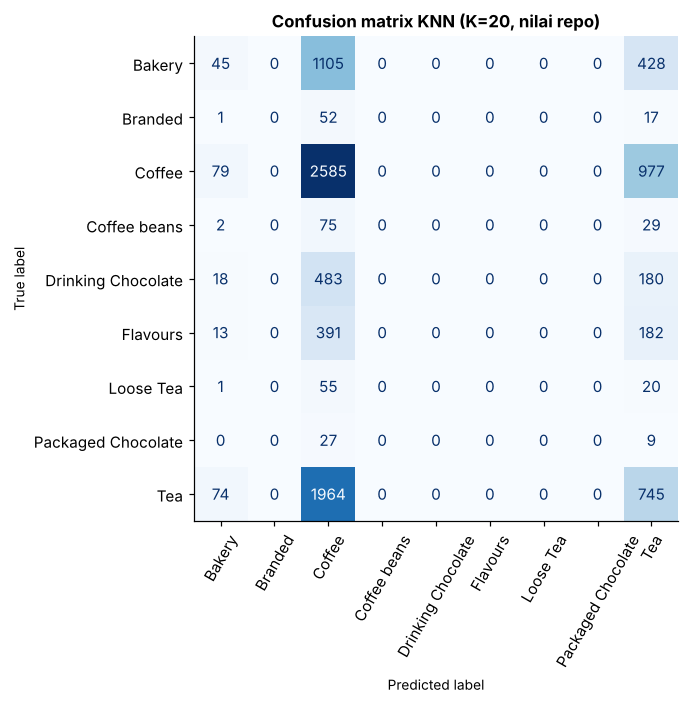

Kelas yang TIDAK pernah diprediksi: ['Branded', 'Coffee beans', 'Drinking Chocolate', 'Flavours', 'Loose Tea', 'Packaged Chocolate']


In [20]:
nama_utama = 'KNN (K=20, nilai repo)'
knn = buat_model(nama_utama).fit(Xtr, ytr); pred = knn.predict(Xte); proba = knn.predict_proba(Xte)
print(classification_report(yte, pred, target_names=KELAS, zero_division=0))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=KELAS).plot(ax=ax, cmap='Blues', xticks_rotation=60, colorbar=False)
ax.set_title(f'Confusion matrix {nama_utama}'); plt.tight_layout(); plt.show()
print('Kelas yang TIDAK pernah diprediksi:', [KELAS[i] for i in range(len(KELAS)) if i not in set(pred)])

In [21]:
# Bootstrap (1000x) pada data uji: interval kepercayaan 95% untuk akurasi
def boot_ci(fn, n, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); vals = [fn(rng.integers(0, n, n)) for _ in range(B)]
    return np.percentile(vals, [2.5, 97.5])
rows = []
for skema, yb in {'acak 80:20': yte, 'temporal Jan-Mei/Jun': yte_t}.items():
    Bk = B_acak if skema.startswith('acak') else B_temp
    for nama in NAMA_MODEL:
        pr = PRED[(skema, nama)]; tg = TGL_ACAK if skema.startswith('acak') else TGL_TEMP
        lo, hi = boot_blok(lambda i: np.mean(pr[i] == yb[i]), tg); lob, hib = boot_ci(lambda i: np.mean(pr[i] == yb[i]), len(yb))
        rows.append({'skema': skema, 'model': nama, 'akurasi_%': round(np.mean(pr == yb)*100, 2), 'CI95_bawah': round(lo*100, 2), 'CI95_atas': round(hi*100, 2), 'CI_baris_bawah': round(lob*100, 2), 'CI_baris_atas': round(hib*100, 2)})
    rows.append({'skema': skema, 'model': 'BASELINE mayoritas', 'akurasi_%': round(Bk['mayoritas']*100, 2), 'CI95_bawah': np.nan, 'CI95_atas': np.nan})
ci_acc = pd.DataFrame(rows).set_index(['skema', 'model']); display(ci_acc)
# KNN utama vs baseline mayoritas: selisih akurasi (bootstrap berpasangan)
majo = np.bincount(ytr).argmax(); pr = PRED[('acak 80:20', nama_utama)]
lo, hi = boot_blok(lambda i: np.mean(pr[i] == yte[i]) - np.mean(yte[i] == majo), TGL_ACAK)
print(f'Selisih akurasi {nama_utama} - baseline mayoritas = {(np.mean(pr==yte)-np.mean(yte==majo))*100:.2f} poin, CI95 [{lo*100:.2f}; {hi*100:.2f}]  (bootstrap per tanggal; CI yang tidak memuat 0 = selisih nyata)')

akurasi_%  CI95_bawah  CI95_atas  CI_baris_bawah  CI_baris_atas
skema                model                                                                                   
acak 80:20           KNN (K=1, F1 makro CV)       28.18       27.21      29.20           27.25          29.05
                     KNN (K=20, nilai repo)       35.31       34.28      36.27           34.38          36.21
                     KNN (K=600, akurasi CV)      38.10       37.04      39.18           37.13          39.06
                     Decision Tree (depth 6)      38.11       37.05      39.21           37.16          39.08
                     Naive Bayes (Gaussian)       38.10       37.04      39.18           37.13          39.06
                     Random Forest (100)          38.11       37.05      39.21           37.16          39.08
                     Logistic Regression          38.10       37.04      39.18           37.13          39.06
                     BASELINE mayoritas           38.10         NaN        NaN             NaN            NaN
temporal Jan-Mei/Jun KNN (K=1, F1 makro CV)       29.12       27.41      30.68           28.25          30.00
                     KNN (K=20, nilai repo)       35.25       34.11      36.47           34.37          36.13
                     KNN (K=600, akurasi CV)      38.79       37.55      40.13           37.85          39.75
                     Decision Tree (depth 6)      38.65       37.42      39.94           37.73          39.59
                     Naive Bayes (Gaussian)       38.79       37.55      40.13           37.85          39.75
                     Random Forest (100)          38.65       37.42      39.94           37.73          39.59
                     Logistic Regression          38.79       37.55      40.13           37.85          39.75
                     BASELINE mayoritas           38.79         NaN        NaN             NaN            NaN

Selisih akurasi KNN (K=20, nilai repo) - baseline mayoritas = -2.78 poin, CI95 [-3.65; -1.98]  (bootstrap per tanggal; CI yang tidak memuat 0 = selisih nyata)


In [22]:
_p = set(PRED[('acak 80:20', nama_utama)]); _tak = [KELAS[i] for i in range(len(KELAS)) if i not in _p]
_r = ci_acc.loc[('acak 80:20', nama_utama)]
_T = '8'
kesimpulan(f'KNN K=20 hanya pernah menebak {len(_p)} dari {len(KELAS)} kelas; tidak pernah menebak: {_tak}.',
           f'Akurasi {_r["akurasi_%"]:.2f}% dengan rentang 95% [{_r["CI95_bawah"]:.2f}; {_r["CI95_atas"]:.2f}], seluruhnya di bawah baseline mayoritas {B_acak["mayoritas"]*100:.2f}%.',
           'Selisih KNN terhadap baseline bernilai negatif dan rentangnya tidak memuat 0: KNN secara nyata TIDAK lebih akurat dari menebak "Coffee". Gunakan kalimat jujur ini di Results.')

KESIMPULAN TAHAP 8
• KNN K=20 hanya pernah menebak 3 dari 9 kelas; tidak pernah menebak: ['Branded', 'Coffee beans',
  'Drinking Chocolate', 'Flavours', 'Loose Tea', 'Packaged Chocolate'].
• Akurasi 35.31% dengan rentang 95% [34.28; 36.27], seluruhnya di bawah baseline mayoritas 38.10%.
• Selisih KNN terhadap baseline bernilai negatif dan rentangnya tidak memuat 0: KNN secara nyata TIDAK
  lebih akurat dari menebak "Coffee". Gunakan kalimat jujur ini di Results.


## Tahap 9 – Tugas keramaian
**Tujuan:** menguji pertanyaan kedua: apakah **jumlah pengunjung** bisa diprediksi dari waktu, termasuk ke bulan yang belum terlihat.

**Label turunan:** jumlah transaksi pada setiap pasangan (tanggal, jam) = tingkat keramaian. Hanya pasangan (tanggal, jam) yang **memiliki minimal satu transaksi** yang tercatat: 2.256 dari 2.715 slot potensial (181 hari × 15 jam). Slot yang kosong dianalisis di 9A-2.

**Dua bentuk tugas**
- **9A Regresi:** memprediksi angka jumlah transaksi. Metrik: **MAE** (rata-rata selisih absolut, dalam satuan transaksi; makin kecil makin baik), **RMSE** (seperti MAE tetapi menghukum selisih besar), **R²** (porsi variasi yang dijelaskan; 1 = sempurna, 0 = sama dengan menebak rata-rata).
- **9B Klasifikasi 3 kelas:** sepi / sedang / ramai, dengan ambang kuartil (Q1 dan Q3) **dari data latih**.

**Tiga skema pengujian (semakin ke bawah semakin ketat)**
1. **Split acak 80:20:** data campur, sehingga model "mengintip" bulan yang sama.
2. **Split temporal:** latih Jan–Mei, uji Juni.
3. **Validasi maju per bulan (forward chaining):** latih bulan 1..m-1, uji bulan m, untuk m = 3, 4, 5, 6. Paling mendekati pemakaian nyata dan memberi empat ulangan.

**Baseline keramaian:** *rata-rata per jam* (rata-rata semua data latih per jam) dan *bulan terakhir* (rata-rata per jam hanya dari bulan terakhir latih; menangkap tren naik). Baseline bulan terakhir hanya bermakna pada uji ke depan, sehingga pada split acak ditandai `NaN` (N/A).

**Cara membaca keluaran**
- Ringkasan angka dan rata-rata transaksi per bulan (terlihat tren naik tajam).
- Tabel MAE/RMSE/R² untuk setiap model dan skema.
- Tabel selisih MAE dengan interval 95%: kolom `kesimpulan` menyatakan model lebih baik / lebih buruk / tidak berbeda nyata (interval per tanggal; interval per baris ditampilkan sebagai pembanding).
- Grafik aktual vs prediksi: titik ideal berada di garis putus. Titik yang mendatar di atas menandakan model tidak bisa memprediksi lonjakan.
- Tabel validasi maju per bulan beserta rata-ratanya.
- Analisis slot kosong dan analisis sensitivitas dengan slot kosong diisi 0.

In [23]:
a = df.groupby(['transaction_date', 'jam', 'hari_minggu', 'is_weekend', 'bulan']).size().reset_index(name='n')
w2 = a['jam'] + 0.5; a['jam_sin'] = np.sin(2*np.pi*w2/24); a['jam_cos'] = np.cos(2*np.pi*w2/24)
F2 = ['jam', 'hari_minggu', 'is_weekend', 'bulan', 'jam_sin', 'jam_cos']; F2_NOM = [c for c in F2 if c != 'bulan']
print('Catatan tanggal-jam:', len(a)); print(a['n'].describe().round(2).to_string())
print('Rata-rata transaksi per jam per bulan:', a.groupby('bulan')['n'].mean().round(2).to_dict())
tr_r, te_r = train_test_split(a, test_size=0.2, random_state=SEED)
tr_t, te_t = a[a.bulan <= 5], a[a.bulan == 6]
rm = lambda yt, yp: {'MAE': mean_absolute_error(yt, yp), 'RMSE': mean_squared_error(yt, yp) ** .5, 'R2': r2_score(yt, yp)}
def knn_reg(k, feat): return Pipeline([('s', StandardScaler()), ('m', KNeighborsRegressor(k))])
def best_k_reg(tr, feat):
    kf = KFold(5, shuffle=True, random_state=SEED); best = None
    for k in [3, 5, 8, 10, 12, 15, 17, 20, 24, 30, 40, 60]:
        s = -cross_val_score(knn_reg(k, feat), tr[feat], tr['n'], cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1).mean()
        if best is None or s < best[1]: best = (k, s)
    return best[0]
K_REG = {}   # K terpilih (CV pada data latih) per skema, dicatat terpisah agar nama model tetap stabil
def jalankan_reg(tr, te, temporal, tag=''):
    out = {}; kk = best_k_reg(tr, F2); kk2 = best_k_reg(tr, F2_NOM); K_REG[tag] = (kk, kk2)
    out['KNN'] = knn_reg(kk, F2).fit(tr[F2], tr['n']).predict(te[F2])
    out['KNN tanpa bulan'] = knn_reg(kk2, F2_NOM).fit(tr[F2_NOM], tr['n']).predict(te[F2_NOM])
    out['Decision Tree'] = DecisionTreeRegressor(max_depth=8, random_state=SEED).fit(tr[F2], tr['n']).predict(te[F2])
    out['Random Forest'] = RandomForestRegressor(200, max_depth=10, random_state=SEED, n_jobs=-1).fit(tr[F2], tr['n']).predict(te[F2])
    out['Baseline: rata-rata per jam'] = te['jam'].map(tr.groupby('jam')['n'].mean()).fillna(tr['n'].mean()).values
    if temporal:
        last = tr[tr.bulan == tr.bulan.max()]
        out['Baseline: bulan terakhir'] = te['jam'].map(last.groupby('jam')['n'].mean()).fillna(last['n'].mean()).values
    return out
PR_REG = {}; TGL_REG = {}; rows = []
for skema, (tr, te, tmp) in {'acak 80:20': (tr_r, te_r, False), 'temporal Jan-Mei/Jun': (tr_t, te_t, True)}.items():
    P = jalankan_reg(tr, te, tmp, skema); PR_REG[skema] = (te['n'].values, P); TGL_REG[skema] = te['transaction_date'].values
    for nama, pr in P.items(): r = rm(te['n'].values, pr); r.update(skema=skema, model=nama); rows.append(r)
    if not tmp: rows.append({'skema': skema, 'model': 'Baseline: bulan terakhir', 'MAE': np.nan, 'RMSE': np.nan, 'R2': np.nan})  # N/A pada split acak
tab_reg = pd.DataFrame(rows).set_index(['skema', 'model']).round(3); display(tab_reg)
print('K terpilih (KNN dengan bulan, KNN tanpa bulan):', K_REG)
print('N/A = baseline bulan terakhir hanya bermakna pada uji temporal.')

Catatan tanggal-jam: 2256
count   2,256.00
mean       21.18
std        13.84
min         1.00
25%        11.00
50%        18.00
75%        28.00
max        85.00
Rata-rata transaksi per jam per bulan: {1: 14.33, 2: 15.12, 3: 17.57, 4: 21.91, 5: 27.66, 6: 30.12}


MAE  RMSE   R2
skema                model                                       
acak 80:20           KNN                          6.15  8.18 0.62
                     KNN tanpa bulan              7.68 10.52 0.37
                     Decision Tree                6.29  8.54 0.58
                     Random Forest                6.37  8.46 0.59
                     Baseline: rata-rata per jam  7.42 10.09 0.42
                     Baseline: bulan terakhir      NaN   NaN  NaN
temporal Jan-Mei/Jun KNN                          8.72 11.98 0.49
                     KNN tanpa bulan             12.13 16.22 0.07
                     Decision Tree                9.10 12.70 0.43
                     Random Forest                8.81 11.81 0.51
                     Baseline: rata-rata per jam 11.93 15.89 0.11
                     Baseline: bulan terakhir     8.14 10.94 0.58

K terpilih (KNN dengan bulan, KNN tanpa bulan): {'acak 80:20': (17, 30), 'temporal Jan-Mei/Jun': (24, 24)}
N/A = baseline bulan terakhir hanya bermakna pada uji temporal.


### 9A-2. Slot jam kosong dan analisis sensitivitas
Tabel di atas hanya memuat jam yang punya minimal satu transaksi. Di sini dihitung **semua** slot jam operasional (06.00–20.59) selama 181 hari, lalu slot tanpa transaksi diperiksa: apakah toko tutup atau memang tidak ada pembeli? Lalu regresi diulang dengan slot kosong diisi **0** sebagai analisis sensitivitas. **Perhatian:** tanpa jadwal buka/tutup toko, slot kosong belum tentu berarti "toko buka tetapi tidak ada pembeli"; bisa juga toko tutup atau data tidak tercatat. Karena itu hasil isi-nol hanya dilaporkan sebagai sensitivitas, bukan hasil utama.

**Cara membaca keluaran**
- *Tabel slot kosong per jam:* jika kekosongan menumpuk di jam tertentu (mis. jam 19–20), itu tanda toko tutup atau data tidak mencatat jam tersebut pada kebanyakan hari, bukan jam sepi yang sesungguhnya.
- *Tabel sensitivitas:* jika urutan model sama seperti di tabel sebelumnya, kesimpulan tidak bergantung pada cara menangani slot kosong.

In [24]:
tgl_all = pd.date_range(df['transaction_date'].min(), df['transaction_date'].max())
slot = pd.MultiIndex.from_product([tgl_all, range(6, 21)], names=['transaction_date', 'jam']).to_frame(index=False)
a_full = slot.merge(a[['transaction_date', 'jam', 'n']], how='left', on=['transaction_date', 'jam']); a_full['n'] = a_full['n'].fillna(0)
a_full['hari_minggu'] = a_full['transaction_date'].dt.dayofweek; a_full['is_weekend'] = (a_full['hari_minggu'] >= 5).astype(int); a_full['bulan'] = a_full['transaction_date'].dt.month
w3 = a_full['jam'] + 0.5; a_full['jam_sin'] = np.sin(2*np.pi*w3/24); a_full['jam_cos'] = np.cos(2*np.pi*w3/24)
kosong = a_full[a_full['n'] == 0]
print(f'Slot potensial: {len(a_full):,} | ada transaksi: {len(a):,} | kosong: {len(kosong):,} | tanggal tanpa transaksi sama sekali: {int((a_full.groupby("transaction_date")["n"].sum() == 0).sum())}')
tab_kosong = kosong.groupby('jam').size().rename('hari_kosong').to_frame(); tab_kosong['dari_181_hari_%'] = (tab_kosong['hari_kosong'] / len(tgl_all) * 100).round(1)
display(tab_kosong.T)
tr_f, te_f = a_full[a_full.bulan <= 5], a_full[a_full.bulan == 6]
P_f = jalankan_reg(tr_f, te_f, True, 'isi-nol'); baris = []
for nama, pr in P_f.items(): r = rm(te_f['n'].values, pr); r.update(model=nama); baris.append(r)
tab_sens = pd.DataFrame(baris).set_index('model').round(3); display(tab_sens[['MAE', 'RMSE', 'R2']])
yf = te_f['n'].values; pk_, pb_ = P_f['KNN'], P_f['Baseline: bulan terakhir']
fdiff = lambda i: np.mean(np.abs(yf[i]-pk_[i])) - np.mean(np.abs(yf[i]-pb_[i]))
sens_lo, sens_hi = boot_blok(fdiff, te_f['transaction_date'].values); sens_d = fdiff(np.arange(len(yf)))
print(f'Slot kosong = 0 (uji Juni, n={len(yf)}): selisih MAE KNN - baseline bulan terakhir = {sens_d:.2f}, CI95 per tanggal [{sens_lo:.2f}; {sens_hi:.2f}]')

Slot potensial: 2,715 | ada transaksi: 2,256 | kosong: 459 | tanggal tanpa transaksi sama sekali: 0


jam,6,13,14,15,16,17,18,19,20
hari_kosong,89.00,7.00,6.00,6.00,6.00,7.00,8.00,165.00,165.00
dari_181_hari_%,49.20,3.90,3.30,3.30,3.30,3.90,4.40,91.20,91.20


,MAE,RMSE,R2
model,,,
KNN,9.03,12.84,0.55
KNN tanpa bulan,11.69,16.36,0.26
Decision Tree,9.10,13.49,0.50
Random Forest,9.23,13.53,0.49
Baseline: rata-rata per jam,11.21,15.67,0.32
Baseline: bulan terakhir,8.35,11.82,0.61


Slot kosong = 0 (uji Juni, n=450): selisih MAE KNN - baseline bulan terakhir = 0.69, CI95 per tanggal [0.30; 1.07]


### 9A (lanjutan) – Apakah selisih dengan baseline nyata?
Selisih MAE = MAE model − MAE baseline. **Negatif = model lebih baik.** Kolom `kesimpulan` memakai interval 95% hasil **bootstrap per tanggal** (berpasangan); kolom `CI_baris_*` adalah bootstrap per baris sebagai pembanding.

In [25]:
rows = []
for skema, (yt, P) in PR_REG.items():
    n = len(yt); tg = TGL_REG[skema]; base = P['Baseline: rata-rata per jam']
    lawan = {'rata-rata per jam': base}
    if 'Baseline: bulan terakhir' in P: lawan['bulan terakhir'] = P['Baseline: bulan terakhir']
    for nama, pr in P.items():
        if nama.startswith('Baseline'): continue
        for ln, bp in lawan.items():
            f = lambda i: np.mean(np.abs(yt[i]-pr[i])) - np.mean(np.abs(yt[i]-bp[i]))
            lo, hi = boot_blok(f, tg); lob, hib = boot_ci(f, n); d = f(np.arange(n))
            rows.append({'skema': skema, 'model': nama, 'lawan': ln, 'selisih_MAE': round(d, 3), 'CI95_bawah': round(lo, 3), 'CI95_atas': round(hi, 3),
                         'CI_baris_bawah': round(lob, 3), 'CI_baris_atas': round(hib, 3),
                         'kesimpulan': 'model LEBIH BAIK' if hi < 0 else 'model LEBIH BURUK' if lo > 0 else 'tidak berbeda nyata'})
ci_reg = pd.DataFrame(rows); display(ci_reg)

,skema,model,lawan,selisih_MAE,CI95_bawah,CI95_atas,CI_baris_bawah,CI_baris_atas,kesimpulan
0,acak 80:20,KNN,rata-rata per jam,-1.27,-1.82,-0.68,-1.80,-0.78,model LEBIH BAIK
1,acak 80:20,KNN tanpa bulan,rata-rata per jam,0.26,0.12,0.42,0.12,0.41,model LEBIH BURUK
2,acak 80:20,Decision Tree,rata-rata per jam,-1.13,-1.79,-0.50,-1.76,-0.56,model LEBIH BAIK
3,acak 80:20,Random Forest,rata-rata per jam,-1.05,-1.72,-0.45,-1.65,-0.48,model LEBIH BAIK
4,temporal Jan-Mei/Jun,KNN,rata-rata per jam,-3.21,-3.88,-2.46,-3.90,-2.48,model LEBIH BAIK
5,temporal Jan-Mei/Jun,KNN,bulan terakhir,0.58,0.16,0.95,0.25,0.91,model LEBIH BURUK
6,temporal Jan-Mei/Jun,KNN tanpa bulan,rata-rata per jam,0.20,0.07,0.33,0.08,0.33,model LEBIH BURUK
7,temporal Jan-Mei/Jun,KNN tanpa bulan,bulan terakhir,3.99,3.04,4.82,3.21,4.77,model LEBIH BURUK
8,temporal Jan-Mei/Jun,Decision Tree,rata-rata per jam,-2.83,-3.60,-1.95,-3.68,-2.01,model LEBIH BAIK
9,temporal Jan-Mei/Jun,Decision Tree,bulan terakhir,0.95,0.48,1.45,0.47,1.51,model LEBIH BURUK


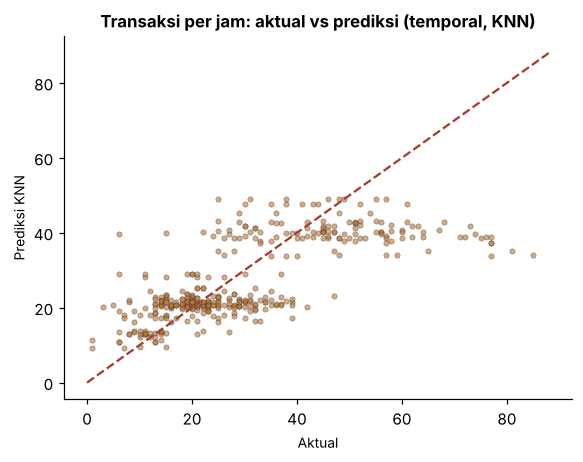

Nilai prediksi maksimum KNN: 49.0 | nilai aktual maksimum: 85 -> KNN tidak bisa memprediksi di atas rentang yang pernah dilihat (tidak ekstrapolasi).


In [26]:
yt, P = PR_REG['temporal Jan-Mei/Jun']; nama_k = 'KNN'
plt.figure(figsize=(5.4, 4.3)); plt.scatter(yt, P[nama_k], s=12, alpha=.6, color='#B5763A', edgecolor='#2B1B12', linewidth=.3)
lim = [0, max(yt.max(), P[nama_k].max()) + 3]; plt.plot(lim, lim, '--', color='#A63D2F'); plt.xlabel('Aktual'); plt.ylabel('Prediksi KNN')
plt.title(f'Transaksi per jam: aktual vs prediksi (temporal, {nama_k})'); plt.tight_layout(); plt.show()
print('Nilai prediksi maksimum KNN:', round(P[nama_k].max(), 1), '| nilai aktual maksimum:', int(yt.max()), '-> KNN tidak bisa memprediksi di atas rentang yang pernah dilihat (tidak ekstrapolasi).')

### 9A (lanjutan) – Validasi maju per bulan
Model dilatih ulang untuk setiap bulan uji (K juga dipilih ulang dari data latih saja, tanpa melihat data uji). Tabel pertama memperlihatkan MAE per bulan uji dan rata-ratanya; tabel kedua memberi rata-rata, simpangan baku, dan R².

In [27]:
# Validasi maju per bulan (forward chaining): latih bulan 1..m-1, uji bulan m
fc = []
for m in [3, 4, 5, 6]:
    tr, te = a[a.bulan < m], a[a.bulan == m]; P = jalankan_reg(tr, te, True, f'maju bulan {m}')
    for nama, pr in P.items(): r = rm(te['n'].values, pr); r.update(bulan_uji=m, model=nama); fc.append(r)
fc = pd.DataFrame(fc)
print('K terpilih per lipatan (dengan bulan, tanpa bulan):', {k: v for k, v in K_REG.items() if k.startswith('maju')})
display(fc.pivot_table(index='model', columns='bulan_uji', values='MAE').round(2).assign(rata2=lambda d: d.mean(axis=1).round(2)).sort_values('rata2'))
ring = fc.groupby('model').agg(MAE_rata2=('MAE', 'mean'), MAE_sd=('MAE', 'std'), R2_rata2=('R2', 'mean')).round(3)
print('Ringkasan 4 lipatan (MAE rata-rata, lebih kecil = lebih baik):'); display(ring.sort_values('MAE_rata2'))

K terpilih per lipatan (dengan bulan, tanpa bulan): {'maju bulan 3': (17, 30), 'maju bulan 4': (17, 12), 'maju bulan 5': (24, 17), 'maju bulan 6': (24, 24)}


bulan_uji,3,4,5,6,rata2
model,,,,,
Baseline: bulan terakhir,5.76,7.02,8.65,8.14,7.39
KNN,5.97,7.10,8.95,8.72,7.68
Random Forest,5.80,7.25,8.92,8.81,7.70
Decision Tree,5.79,7.22,8.78,9.10,7.72
Baseline: rata-rata per jam,5.87,7.84,11.37,11.93,9.25
KNN tanpa bulan,6.03,7.97,11.53,12.13,9.42


Ringkasan 4 lipatan (MAE rata-rata, lebih kecil = lebih baik):


,MAE_rata2,MAE_sd,R2_rata2
model,,,
Baseline: bulan terakhir,7.39,1.28,0.47
KNN,7.68,1.41,0.40
Random Forest,7.69,1.48,0.41
Decision Tree,7.72,1.53,0.40
Baseline: rata-rata per jam,9.25,2.89,0.21
KNN tanpa bulan,9.42,2.91,0.18


In [28]:
_t = tab_reg.loc['temporal Jan-Mei/Jun']; _ac = tab_reg.loc['acak 80:20']
_c1 = ci_reg[(ci_reg.skema == 'acak 80:20') & (ci_reg.model == 'KNN')].iloc[0]
_c2 = ci_reg[(ci_reg.skema != 'acak 80:20') & (ci_reg.model == 'KNN') & (ci_reg.lawan == 'bulan terakhir')].iloc[0]
_T = '9A'
kesimpulan(f'Split acak: KNN MAE {_ac.loc["KNN","MAE"]:.2f} vs baseline rata-rata per jam {_ac.loc["Baseline: rata-rata per jam","MAE"]:.2f}; selisih {_c1.selisih_MAE:.2f} (CI [{_c1.CI95_bawah:.2f}; {_c1.CI95_atas:.2f}]) -> {_c1.kesimpulan}.',
           f'Uji ke depan (Juni): KNN MAE {_t.loc["KNN","MAE"]:.2f} vs baseline bulan terakhir {_t.loc["Baseline: bulan terakhir","MAE"]:.2f}; selisih {_c2.selisih_MAE:.2f} (CI [{_c2.CI95_bawah:.2f}; {_c2.CI95_atas:.2f}]) -> {_c2.kesimpulan}.',
           f'Validasi maju (rata-rata 4 bulan): KNN {ring.loc["KNN","MAE_rata2"]:.2f} vs baseline bulan terakhir {ring.loc["Baseline: bulan terakhir","MAE_rata2"]:.2f}.',
           f'Analisis sensitivitas (slot jam kosong diisi 0): KNN MAE {tab_sens.loc["KNN","MAE"]:.2f} vs baseline bulan terakhir {tab_sens.loc["Baseline: bulan terakhir","MAE"]:.2f}; selisih {sens_d:.2f} (CI per tanggal [{sens_lo:.2f}; {sens_hi:.2f}]). Urutan model tidak berubah, jadi kesimpulan tidak bergantung pada cara menangani slot kosong.',
           f'Fitur BULAN sangat penting: tanpa bulan, MAE KNN pada Juni naik dari {_t.loc["KNN","MAE"]:.2f} menjadi {_t.loc["KNN tanpa bulan","MAE"]:.2f}, karena jumlah transaksi per jam naik terus setiap bulan.',
           'KNN unggul pada split acak, tetapi keunggulan itu hilang saat diuji ke masa depan karena KNN tidak bisa memprediksi di atas nilai yang pernah dilihat (tidak ekstrapolasi tren). Laporkan kedua skema.')

KESIMPULAN TAHAP 9A
• Split acak: KNN MAE 6.15 vs baseline rata-rata per jam 7.42; selisih -1.27 (CI [-1.82; -0.68]) -> model
  LEBIH BAIK.
• Uji ke depan (Juni): KNN MAE 8.72 vs baseline bulan terakhir 8.14; selisih 0.58 (CI [0.16; 0.95]) ->
  model LEBIH BURUK.
• Validasi maju (rata-rata 4 bulan): KNN 7.68 vs baseline bulan terakhir 7.39.
• Analisis sensitivitas (slot jam kosong diisi 0): KNN MAE 9.03 vs baseline bulan terakhir 8.35; selisih
  0.69 (CI per tanggal [0.30; 1.07]). Urutan model tidak berubah, jadi kesimpulan tidak bergantung pada
  cara menangani slot kosong.
• Fitur BULAN sangat penting: tanpa bulan, MAE KNN pada Juni naik dari 8.72 menjadi 12.13, karena jumlah
  transaksi per jam naik terus setiap bulan.
• KNN unggul pada split acak, tetapi keunggulan itu hilang saat diuji ke masa depan karena KNN tidak bisa
  memprediksi di atas nilai yang pernah dilihat (tidak ekstrapolasi tren). Laporkan kedua skema.


### 9B – Klasifikasi keramaian 3 kelas
Mengubah angka transaksi menjadi tiga kelas lebih mudah dipakai pengelola (siapkan staf lebih banyak saat "ramai"). Ambang **sepi** = di bawah atau sama dengan kuartil 1, **ramai** = di atas kuartil 3, selebihnya **sedang** (kuartil dihitung dari data latih setiap skema).

**Cara membaca keluaran:** tabel akurasi dan F1 makro tiap model dan skema, lalu rata-rata validasi maju. F1 makro juga dihitung untuk kedua baseline, sehingga perbandingan kelas sepi/sedang/ramai adil. Setelah itu confusion matrix 3 kelas dan laporan per kelas untuk KNN, beserta interval 95%.

In [29]:
# 9B. Klasifikasi keramaian 3 kelas (ambang kuartil dari DATA LATIH di setiap skema)
NAMA3 = ['sepi', 'sedang', 'ramai']
def label3(tr, te):
    q1, q3 = tr['n'].quantile([.25, .75]); f = lambda s: np.where(s <= q1, 0, np.where(s <= q3, 1, 2)); return f(tr['n']), f(te['n']), q1, q3
cls3 = {'KNN (K=15)': lambda: Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(15))]),
        'Decision Tree': lambda: DecisionTreeClassifier(max_depth=6, random_state=SEED),
        'Naive Bayes': lambda: GaussianNB(),
        'Random Forest': lambda: RandomForestClassifier(200, max_depth=8, random_state=SEED, n_jobs=-1)}
def jalankan3(tr, te):
    ytr3, yte3, q1, q3 = label3(tr, te); res = []
    pm_ = np.full(len(yte3), np.bincount(ytr3).argmax()); res.append({'model': 'Baseline mayoritas', 'akurasi': float(np.mean(pm_ == yte3)), 'f1_makro': f1_score(yte3, pm_, average='macro', zero_division=0)})
    mj = pd.Series(ytr3, index=tr.index).groupby(tr['jam']).agg(lambda s: s.mode()[0])
    pj_ = te['jam'].map(mj).fillna(1).astype(int).values; res.append({'model': 'Baseline modus per jam', 'akurasi': float(np.mean(pj_ == yte3)), 'f1_makro': f1_score(yte3, pj_, average='macro', zero_division=0)})
    for nama, mk in cls3.items():
        p_ = mk().fit(tr[F2], ytr3).predict(te[F2]); res.append({'model': nama, 'akurasi': accuracy_score(yte3, p_), 'f1_makro': f1_score(yte3, p_, average='macro')})
    return res, (q1, q3), np.bincount(yte3, minlength=3)
out3 = []
for skema, (tr, te) in {'acak 80:20': (tr_r, te_r), 'temporal Jan-Mei/Jun': (tr_t, te_t)}.items():
    res, (q1, q3), kc = jalankan3(tr, te); print(f'{skema}: Q1={q1:.1f}, Q3={q3:.1f}, n uji={len(te)}, kelas uji (sepi/sedang/ramai)={kc.tolist()}')
    for r in res: r['skema'] = skema; out3.append(r)
for m in [3, 4, 5, 6]:
    res, _, _ = jalankan3(a[a.bulan < m], a[a.bulan == m])
    for r in res: r['skema'] = f'maju: uji bulan {m}'; out3.append(r)
tab3 = pd.DataFrame(out3).set_index(['skema', 'model']).round(4); display((tab3 * 100).round(2))
fw = tab3.loc[[s for s in tab3.index.get_level_values(0).unique() if s.startswith('maju')]].groupby(level='model')[['akurasi', 'f1_makro']].mean().mul(100).round(2)
print('Rata-rata 4 lipatan maju:'); display(fw.sort_values('akurasi', ascending=False))

acak 80:20: Q1=11.0, Q3=28.0, n uji=452, kelas uji (sepi/sedang/ramai)=[116, 238, 98]


temporal Jan-Mei/Jun: Q1=10.0, Q3=26.0, n uji=375, kelas uji (sepi/sedang/ramai)=[26, 165, 184]


akurasi  f1_makro
skema                model                                    
acak 80:20           Baseline mayoritas        52.65     23.00
                     Baseline modus per jam    58.63     56.07
                     KNN (K=15)                67.04     65.96
                     Decision Tree             66.15     66.65
                     Naive Bayes               58.85     59.32
                     Random Forest             65.93     65.48
temporal Jan-Mei/Jun Baseline mayoritas        44.00     20.37
                     Baseline modus per jam    73.33     65.93
                     KNN (K=15)                72.53     57.31
                     Decision Tree             71.47     58.71
                     Naive Bayes               71.47     65.26
                     Random Forest             72.53     59.90
maju: uji bulan 3    Baseline mayoritas        46.37     21.12
                     Baseline modus per jam    67.36     64.10
                     KNN (K=15)                62.95     59.76
                     Decision Tree             63.21     60.42
                     Naive Bayes               63.99     61.57
                     Random Forest             65.03     62.42
maju: uji bulan 4    Baseline mayoritas        45.16     20.74
                     Baseline modus per jam    70.70     65.89
                     KNN (K=15)                66.94     62.35
                     Decision Tree             69.09     63.55
                     Naive Bayes               64.78     60.61
                     Random Forest             65.32     58.50
maju: uji bulan 5    Baseline mayoritas        41.90     19.69
                     Baseline modus per jam    74.29     68.21
                     KNN (K=15)                74.04     60.69
                     Decision Tree             73.52     66.16
                     Naive Bayes               70.44     63.59
                     Random Forest             72.75     61.19
maju: uji bulan 6    Baseline mayoritas        44.00     20.37
                     Baseline modus per jam    73.33     65.93
                     KNN (K=15)                72.53     57.31
                     Decision Tree             71.47     58.71
                     Naive Bayes               71.47     65.26
                     Random Forest             72.53     59.90

Rata-rata 4 lipatan maju:


,akurasi,f1_makro
model,,
Baseline modus per jam,71.42,66.03
Decision Tree,69.32,62.21
KNN (K=15),69.11,60.03
Random Forest,68.91,60.50
Naive Bayes,67.67,62.76
Baseline mayoritas,44.36,20.48


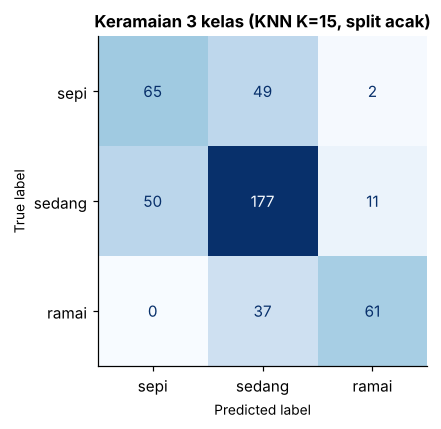

              precision    recall  f1-score   support

        sepi       0.57      0.56      0.56       116
      sedang       0.67      0.74      0.71       238
       ramai       0.82      0.62      0.71        98

    accuracy                           0.67       452
   macro avg       0.69      0.64      0.66       452
weighted avg       0.68      0.67      0.67       452



Akurasi KNN = 67.04%, CI95 per tanggal [62.14; 71.49]


In [30]:
ytr3, yte3, q1, q3 = label3(tr_r, te_r)
m = cls3['KNN (K=15)']().fit(tr_r[F2], ytr3); pr3 = m.predict(te_r[F2])
fig, ax = plt.subplots(figsize=(4.6, 4)); ConfusionMatrixDisplay(confusion_matrix(yte3, pr3), display_labels=NAMA3).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Keramaian 3 kelas (KNN K=15, split acak)'); plt.tight_layout(); plt.show()
print(classification_report(yte3, pr3, target_names=NAMA3, zero_division=0))
lo, hi = boot_blok(lambda i: np.mean(pr3[i] == yte3[i]), te_r['transaction_date'].values); print(f'Akurasi KNN = {np.mean(pr3==yte3)*100:.2f}%, CI95 per tanggal [{lo*100:.2f}; {hi*100:.2f}]')

In [31]:
_s = tab3.loc['acak 80:20']; _tp = tab3.loc['temporal Jan-Mei/Jun']
_T = '9B'
kesimpulan(f'Split acak: KNN {_s.loc["KNN (K=15)","akurasi"]*100:.2f}% vs baseline mayoritas {_s.loc["Baseline mayoritas","akurasi"]*100:.2f}% dan baseline modus per jam {_s.loc["Baseline modus per jam","akurasi"]*100:.2f}%.',
           f'Uji ke depan (Juni): akurasi KNN {_tp.loc["KNN (K=15)","akurasi"]*100:.2f}% vs baseline modus per jam {_tp.loc["Baseline modus per jam","akurasi"]*100:.2f}% (selisih kecil), tetapi F1 makro KNN {_tp.loc["KNN (K=15)","f1_makro"]*100:.2f}% vs baseline {_tp.loc["Baseline modus per jam","f1_makro"]*100:.2f}%: aturan sederhana "per jam" lebih baik pada kelas yang jarang (di Juni kelas sepi hanya sedikit).',
           f'Validasi maju: akurasi rata-rata KNN {fw.loc["KNN (K=15)","akurasi"]:.2f}% vs baseline modus per jam {fw.loc["Baseline modus per jam","akurasi"]:.2f}%.',
           'Pada split acak KNN mengungguli baseline mayoritas dan modus per jam, tetapi pada uji ke depan KNN tidak mengungguli aturan per jam (akurasi sama, F1 makro lebih rendah). Hasil split acak tidak boleh dipakai sebagai bukti bahwa KNN efektif untuk keramaian 3 kelas.')

KESIMPULAN TAHAP 9B
• Split acak: KNN 67.04% vs baseline mayoritas 52.65% dan baseline modus per jam 58.63%.
• Uji ke depan (Juni): akurasi KNN 72.53% vs baseline modus per jam 73.33% (selisih kecil), tetapi F1
  makro KNN 57.31% vs baseline 65.93%: aturan sederhana "per jam" lebih baik pada kelas yang jarang (di
  Juni kelas sepi hanya sedikit).
• Validasi maju: akurasi rata-rata KNN 69.11% vs baseline modus per jam 71.42%.
• Pada split acak KNN mengungguli baseline mayoritas dan modus per jam, tetapi pada uji ke depan KNN
  tidak mengungguli aturan per jam (akurasi sama, F1 makro lebih rendah). Hasil split acak tidak boleh
  dipakai sebagai bukti bahwa KNN efektif untuk keramaian 3 kelas.


## Tahap 10 – Ringkasan otomatis dan penyimpanan
**Tujuan:** merangkum jawaban penelitian dalam satu tabel yang dibuat dari angka hasil, lalu menyimpan semua tabel ke berkas CSV.

**Cara membaca keluaran:** kolom *Pertanyaan* dan *Jawaban dari data* berisi YA/TIDAK dan angka pendukung. Berkas CSV disimpan di folder `hasil/`, dikompres menjadi `hasil_eksperimen_v2.zip`, dan terunduh otomatis di Colab.

| Berkas CSV | Isi |
|---|---|
| `kualitas_data.csv` | hasil pemeriksaan kualitas dan SHA-256 |
| `pemilihan_k.csv` | akurasi dan F1 CV untuk tiap K |
| `eksperimen_knn_grid.csv` | hasil grid search KNN |
| `perbandingan_model_kategori.csv` | metrik semua model (label menu) |
| `eksperimen_imbalance.csv` | oversampling dan class_weight |
| `interval_kepercayaan_akurasi.csv` | akurasi dengan rentang 95% |
| `regresi_keramaian.csv` | MAE/RMSE/R² |
| `interval_kepercayaan_mae.csv` | selisih MAE dengan rentang 95% |
| `validasi_maju_regresi.csv` | hasil per bulan uji |
| `klasifikasi_keramaian_3kelas.csv` | akurasi dan F1 keramaian 3 kelas |
| `sensitivitas_slot_kosong.csv` | regresi keramaian dengan slot jam kosong diisi 0 (analisis sensitivitas) |
| `slot_kosong_per_jam.csv` | jumlah hari kosong per jam |
| `k_temporal_bersih.csv` | K dipilih hanya dari Jan–Mei dan hasilnya pada Juni |
| `ringkasan_otomatis.csv` | tabel ringkasan |

In [32]:
def ya(b): return 'YA' if b else 'TIDAK'
acc = tab_model.loc[('acak 80:20', nama_utama), 'akurasi']; maj = B_acak['mayoritas']
t3k = tab_model.loc[('acak 80:20', nama_utama), 'top3']; b3 = B_acak['top3_terpopuler']
ringkas = [
 ['Data lulus gerbang kualitas', ya(qc['total_missing'] == 0 and qc['duplikat_transaction_id'] == 0)],
 ['Cramér V kategori x segmen', f'{V:.4f} ' + ('(sangat lemah)' if V < 0.1 else '(ada asosiasi)')],
 ['Kruskal-Wallis volume x jam', f'H={H:.0f}, p={pk:.2g}'],
 [f'{nama_utama} mengungguli baseline mayoritas (akurasi)?', f'{ya(acc > maj)} ({acc*100:.2f}% vs {maj*100:.2f}%)'],
 [f'{nama_utama} mengungguli baseline top-3?', f'{ya(t3k > b3)} ({t3k*100:.2f}% vs {b3*100:.2f}%)'],
 ['Baseline modus jam-hari mengungguli mayoritas?', f'{ya(B_acak["modus_jam_hari"] > B_acak["mayoritas"] + 0.005)} ({B_acak["modus_jam_hari"]*100:.2f}% vs {B_acak["mayoritas"]*100:.2f}%)'],
 ['Sel jam-hari yang modusnya Coffee', f'{int((modus_all == "Coffee").sum())} dari {len(modus_all)}'],
 ['Kelas tak pernah diprediksi KNN utama', ', '.join(KELAS[i] for i in range(len(KELAS)) if i not in set(PRED[("acak 80:20", nama_utama)])) or '-'],
]
rg = tab_reg.loc['temporal Jan-Mei/Jun']; knn_t = 'KNN'
ringkas += [['Keramaian (temporal): MAE KNN vs baseline bulan terakhir', f'{rg.loc[knn_t, "MAE"]:.2f} vs {rg.loc["Baseline: bulan terakhir", "MAE"]:.2f}'],
            ['Keramaian (validasi maju): MAE rata-rata KNN vs baseline bulan terakhir', f'{ring.loc["KNN", "MAE_rata2"]:.2f} vs {ring.loc["Baseline: bulan terakhir", "MAE_rata2"]:.2f}'],
            ['Keramaian (acak): MAE KNN vs rata-rata per jam', f'{tab_reg.loc[("acak 80:20", "KNN"), "MAE"]:.2f} vs {tab_reg.loc[("acak 80:20", "Baseline: rata-rata per jam"), "MAE"]:.2f}']]
ringkas += [['Keramaian (slot kosong diisi 0, uji Juni): MAE KNN vs baseline bulan terakhir', f'{tab_sens.loc["KNN", "MAE"]:.2f} vs {tab_sens.loc["Baseline: bulan terakhir", "MAE"]:.2f}'],
            ['Keramaian 3 kelas (temporal): F1 makro KNN vs baseline modus per jam', f'{tab3.loc[("temporal Jan-Mei/Jun", "KNN (K=15)"), "f1_makro"]*100:.2f}% vs {tab3.loc[("temporal Jan-Mei/Jun", "Baseline modus per jam"), "f1_makro"]*100:.2f}%']]
rk = pd.DataFrame(ringkas, columns=['Pertanyaan', 'Jawaban dari data'])
rk.index = range(1, len(rk) + 1)
display(rk.style.set_properties(**{'text-align': 'left', 'white-space': 'normal'}).set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}]))

os.makedirs('hasil', exist_ok=True)
tab_model.to_csv('hasil/perbandingan_model_kategori.csv'); tab_imb.to_csv('hasil/eksperimen_imbalance.csv'); exp_knn.to_csv('hasil/eksperimen_knn_grid.csv', index=False)
tab_reg.to_csv('hasil/regresi_keramaian.csv'); tab3.to_csv('hasil/klasifikasi_keramaian_3kelas.csv'); ci_acc.to_csv('hasil/interval_kepercayaan_akurasi.csv')
ci_reg.to_csv('hasil/interval_kepercayaan_mae.csv', index=False); fc.to_csv('hasil/validasi_maju_regresi.csv', index=False); rk.to_csv('hasil/ringkasan_otomatis.csv', index=False)
tab_sens.to_csv('hasil/sensitivitas_slot_kosong.csv'); tab_kosong.to_csv('hasil/slot_kosong_per_jam.csv'); tab_k_temporal.to_csv('hasil/k_temporal_bersih.csv')
pd.DataFrame({'K': ks, 'akurasi_cv': cv_acc, 'f1_makro_cv': cv_f1}).to_csv('hasil/pemilihan_k.csv', index=False)
pd.Series({**{k: str(v) for k, v in qc.items()}, 'sha256_data': sha, 'sklearn': sklearn.__version__}, name='nilai').to_csv('hasil/kualitas_data.csv')
print('Berkas hasil:', sorted(os.listdir('hasil')))
try:
    import shutil; shutil.make_archive('hasil_eksperimen_v2', 'zip', 'hasil')
    from google.colab import files; files.download('hasil_eksperimen_v2.zip')
except ImportError: pass

,Pertanyaan,Jawaban dari data
1,Data lulus gerbang kualitas,YA
2,Cramér V kategori x segmen,0.0335 (sangat lemah)
3,Kruskal-Wallis volume x jam,"H=1017, p=3.8e-208"
4,"KNN (K=20, nilai repo) mengungguli baseline mayoritas (akurasi)?",TIDAK (35.31% vs 38.10%)
5,"KNN (K=20, nilai repo) mengungguli baseline top-3?",TIDAK (77.83% vs 83.73%)
6,Baseline modus jam-hari mengungguli mayoritas?,TIDAK (38.11% vs 38.10%)
7,Sel jam-hari yang modusnya Coffee,97 dari 105
8,Kelas tak pernah diprediksi KNN utama,"Branded, Coffee beans, Drinking Chocolate, Flavours, Loose Tea, Packaged Chocolate"
9,Keramaian (temporal): MAE KNN vs baseline bulan terakhir,8.72 vs 8.14
10,Keramaian (validasi maju): MAE rata-rata KNN vs baseline bulan terakhir,7.68 vs 7.39


Berkas hasil: ['eksperimen_imbalance.csv', 'eksperimen_knn_grid.csv', 'interval_kepercayaan_akurasi.csv', 'interval_kepercayaan_mae.csv', 'k_temporal_bersih.csv', 'klasifikasi_keramaian_3kelas.csv', 'kualitas_data.csv', 'pemilihan_k.csv', 'perbandingan_model_kategori.csv', 'regresi_keramaian.csv', 'ringkasan_otomatis.csv', 'sensitivitas_slot_kosong.csv', 'slot_kosong_per_jam.csv', 'validasi_maju_regresi.csv']


## Penutup – Cara menarik kesimpulan untuk laporan

1. **Label:** `product_category` (9 kelas) sudah ada di dataset; label keramaian diturunkan dari jumlah transaksi per jam.
2. **Kualitas data:** tidak ada missing value maupun duplikat (Tahap 2).
3. **Menu vs waktu (P1):** hubungan sangat lemah (Cramér V). KNN dan model lain tidak melampaui baseline mayoritas, dan baseline top-3 mengalahkan top-3 KNN. Laporkan sebagai temuan, bukan kegagalan.
4. **Pemilihan K:** akurasi CV mengejar baseline saat K membesar, F1 makro turun; tidak ada K yang unggul (Tahap 6).
5. **Imbalance:** tidak membantu; eksperimen negatif (Tahap 7).
6. **Keramaian (P2):** KNN unggul pada split acak, tetapi pada uji ke depan baseline "bulan terakhir" mengalahkannya (juga ketika slot jam kosong diisi 0, dan dengan interval per tanggal). Pada klasifikasi 3 kelas, F1 makro baseline modus per jam lebih tinggi daripada KNN pada uji ke depan. Fitur bulan sangat menentukan.
7. **Keterbatasan:** dataset simulasi, satu cabang, enam bulan, tanpa ID pelanggan, fitur hanya jam dan hari, KNN tidak bisa mengekstrapolasi tren.

**Saran lanjutan:** data nyata dari beberapa tahun, fitur tambahan (cuaca, hari libur, promosi), dan model deret waktu untuk keramaian.